# COS711 Assignment 2: Data Preparation
### Solar Filament Segmentation Challenge 2026 (MAGFiLO)

This notebook is our data-preparation milestone. Every code cell has two notes:
- **Above the cell (What & why):** what we are checking and why it matters for this problem.
- **Below the cell (Interpretation):** what the output shows and the decision we took from it.

**Sources we rely on**
- The assignment brief (COS711-A2).
- The official Kaggle pages: Data, Evaluation, Leaderboard Ranking, Submission File.
- The organisers' self-evaluation notebook, which contains the exact scoring code.
- The MAGFiLO paper: Ahmadzadeh et al., *Scientific Data* 11:1031 (2024).

We use only the data from the Kaggle Data page. No external labels are used for the test images.

**The problem in one paragraph.** Each image is a full-disk H-alpha photo of the Sun. Filaments are thin dark threads on the disk. We must output one mask per filament. Kaggle scores this with **Panoptic Quality (PQ)**, which counts a filament as found only if our mask overlaps it with IoU > 0.5. It also penalises every extra or missed filament. So data prep has to answer two questions: what makes this hard, and how do we prepare the data so a model can learn it without fooling ourselves in validation?

## 0. Setup
**What & why.** We load the libraries, fix the random seed so every number in this notebook can be reproduced, and locate the data. The same notebook runs locally or on Kaggle without edits. `pycocotools` is imported because the competition's ground truth is built with it (Kaggle Data page). We must draw masks exactly the way Kaggle does.

In [ ]:
import os, json, math, random, time, collections
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedGroupKFold
from pycocotools import mask as mask_util   # pip install pycocotools (official GT format)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 90

ON_KAGGLE = Path("/kaggle/input").exists()
ANN_NAME = "MAGFiLO_1.0_Annotations_kaggle2026_train.json"

def find_data_root():
    # Returns the MAGFiLO_1.0_Kaggle_2026 folder (the one containing train/ and test/).
    env = os.environ.get("MAGFILO_ROOT")
    search = ([Path(env)] if env else []) + [Path("/kaggle/input"), Path.cwd(), Path.cwd().parent]
    for base in search:
        if base.exists():
            hits = list(base.glob(f"**/{ANN_NAME}"))
            if hits:
                return hits[0].parent.parent
    raise FileNotFoundError(f"Could not find {ANN_NAME}; set MAGFILO_ROOT")

DATA_ROOT = find_data_root()
ANN_PATH = DATA_ROOT / "train" / ANN_NAME
TRAIN_IMG_DIR = DATA_ROOT / "train" / "train_images"
TEST_IMG_DIR = DATA_ROOT / "test" / "test_images"
OUT_DIR = Path("/kaggle/working/prepared") if ON_KAGGLE else Path.cwd() / "prepared"

EXPORT = True          # write the prepared dataset to OUT_DIR
N_FOLDS = 5
IMG_SIZE = 2048

# GONG H-alpha network: the letter after the timestamp in the file name is the site
SITES = {"B": "Big Bear (USA)", "C": "Cerro Tololo (Chile)", "L": "Learmonth (Australia)",
         "M": "Mauna Loa (USA)", "T": "El Teide (Spain)", "U": "Udaipur (India)"}
print("DATA_ROOT:", DATA_ROOT)
print("OUT_DIR  :", OUT_DIR)

c:\Users\lusiz\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DATA_ROOT: c:\Users\lusiz\Desktop\University of Pretoria\COS711-AI\Assignment 2\filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026
OUT_DIR  : c:\Users\lusiz\Desktop\University of Pretoria\COS711-AI\Assignment 2\data_prep\prepared


**Interpretation.** The data folder was found and the output folder is `prepared/`. Everything below runs from the raw Kaggle files.

## 1. What is in the dataset?
**What & why.** Before any modelling we need to know what one training example actually is. The labels are a COCO-style JSON. The Kaggle Data page warns that one image can be annotated several times by different annotators, so we count observations (JPEG files) and annotation sets (COCO "images") separately. We also check that every file exists, and we look at the label types.

In [2]:
with open(ANN_PATH) as f:
    coco = json.load(f)

print(coco["info"]["description"], "| version", coco["info"]["version"], "| updated", coco["info"].get("date_updated"))
CATS = {c["id"]: c["name"] for c in coco["categories"]}
print("Categories:", CATS)

sets_df = pd.DataFrame(coco["images"]).rename(columns={"id": "set_id"})
ann_df = pd.DataFrame(coco["annotations"]).rename(columns={"image_id": "set_id", "id": "ann_id"})
print(f"annotation sets (COCO images): {len(sets_df)} | filament annotations: {len(ann_df)}")
print("image fields:", list(coco["images"][0].keys()))
print("annotation fields:", list(coco["annotations"][0].keys()))

def parse_name(fn):
    # e.g. 20140609195854Bh.jpeg -> (timestamp, site letter)
    return pd.Timestamp(datetime.strptime(fn[:14], "%Y%m%d%H%M%S")), fn[14]

sets_df["obs"] = sets_df.file_name.str.replace(".jpeg", "", regex=False)
sets_df["set_code"] = sets_df.set_id.str.split("-").str[0]
sets_df["time"], sets_df["site"] = zip(*sets_df.file_name.map(parse_name))
assert (sets_df.set_id == sets_df.set_code + "-" + sets_df.obs).all()
assert sets_df[["height", "width"]].eq(IMG_SIZE).all().all()

n_fil = ann_df.groupby("set_id").size().rename("n_filaments")
sets_df = sets_df.merge(n_fil, left_on="set_id", right_index=True, how="left").fillna({"n_filaments": 0})

obs_df = (sets_df.groupby("obs")
          .agg(file_name=("file_name", "first"), time=("time", "first"), site=("site", "first"),
               n_sets=("set_id", "size"), mean_filaments=("n_filaments", "mean"))
          .reset_index())
test_files = sorted(p.name for p in TEST_IMG_DIR.glob("*.jpeg"))
test_df = pd.DataFrame({"file_name": test_files})
test_df["obs"] = test_df.file_name.str.replace(".jpeg", "", regex=False)
test_df["time"], test_df["site"] = zip(*test_df.file_name.map(parse_name))

disk_files = set(p.name for p in TRAIN_IMG_DIR.glob("*.jpeg"))
print(f"train observations: {len(obs_df)} (on disk: {len(disk_files)}, missing: {len(set(obs_df.file_name) - disk_files)})")
print(f"test observations : {len(test_df)}")
print("annotation sets per observation:", obs_df.n_sets.value_counts().sort_index().to_dict())
print("annotations per category:", ann_df.category_id.map(CATS).value_counts().to_dict())
print("polygons per annotation:", ann_df.segmentation.map(len).value_counts().to_dict(),
      "| iscrowd:", ann_df.iscrowd.value_counts().to_dict())

MLEcoFi 2024 Dataset - V1.0 | version 1.0 | updated 2026-06-01
Categories: {1: 'Left', 2: 'Right', 3: 'Unidentifiable', 4: 'Ambiguous'}
annotation sets (COCO images): 1154 | filament annotations: 8199
image fields: ['license', 'file_name', 'url', 'height', 'width', 'date_captured', 'id']
annotation fields: ['segmentation', 'area', 'iscrowd', 'spine', 'image_id', 'bbox', 'category_id', 'id']
train observations: 707 (on disk: 707, missing: 0)
test observations : 180
annotation sets per observation: {1: 411, 2: 145, 3: 151}
annotations per category: {'Unidentifiable': 3074, 'Right': 2590, 'Left': 2535}
polygons per annotation: {1: 8199} | iscrowd: {0: 8199}


**Interpretation.**
- **707 training photos** carry **1,154 annotation sets** with **8,199 filaments**. There are **180 test photos**.
- **296 photos were labelled more than once**: 145 by two people, 151 by three. This comes from MAGFiLO's double-blind protocol, where groups of three annotators labelled copies of the same batch (paper, "Manual Annotation").
  - *Consequence 1:* the same photo appears up to 3 times, so a naive split could put copies of one photo in both train and validation. Section 8 handles this.
  - *Consequence 2:* there is no single "truth" for these photos. Section 6 measures how much the annotators disagree.
- Every filament is **one polygon** (`iscrowd = 0`, one polygon each), as MAGFiLO required one-piece, hole-free masks. We never need to merge several polygons into one instance.
- Labels: Left 2,535, Right 2,590, Unidentifiable 3,074, Ambiguous 0. These are magnetic **chirality** classes. Kaggle's PQ ignores classes (it is a single "filament" class), so chirality is at most an optional extra training signal.
- No files are missing, so no cleaning of broken references is needed.

**What & why: train vs test, and time.** We compare how the photos are spread over sites and years in train and test. If the test set came from different instruments or years, our validation would need to reflect that. We also count photos taken close together in time, because those show the same filaments (this decides the split in Section 8).

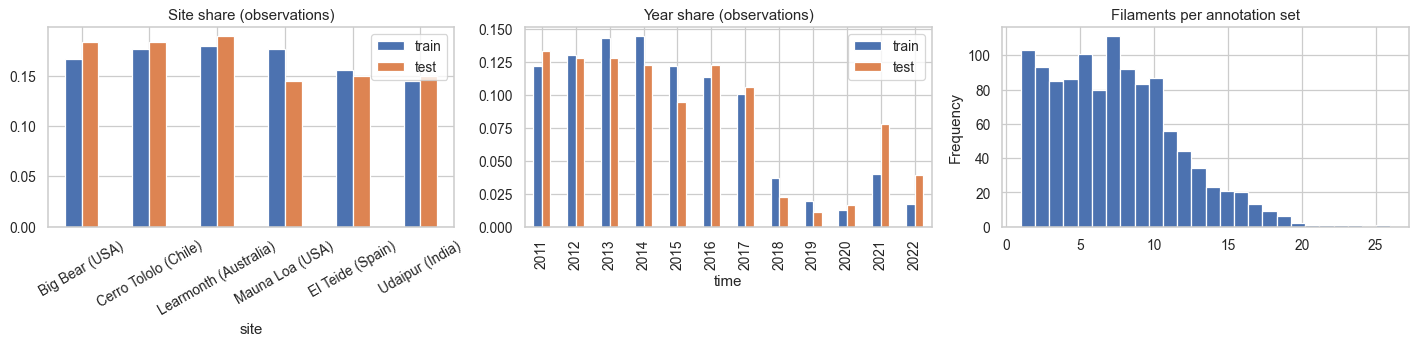

unique train days: 656 | consecutive train obs < 24 h apart: 119
test days also present in train: 31 of 176


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
site_cmp = pd.DataFrame({"train": obs_df.site.value_counts(normalize=True),
                         "test": test_df.site.value_counts(normalize=True)}).sort_index()
site_cmp.rename(index=SITES).plot.bar(ax=ax[0], rot=30, title="Site share (observations)")
yr = pd.DataFrame({"train": obs_df.time.dt.year.value_counts(normalize=True),
                   "test": test_df.time.dt.year.value_counts(normalize=True)}).sort_index()
yr.plot.bar(ax=ax[1], title="Year share (observations)")
sets_df.n_filaments.plot.hist(bins=26, ax=ax[2], title="Filaments per annotation set")
plt.tight_layout(); plt.show()

# temporal proximity
t = obs_df.time.sort_values().reset_index(drop=True)
gaps_h = t.diff().dt.total_seconds().div(3600).dropna()
train_days, test_days = set(obs_df.time.dt.date), set(test_df.time.dt.date)
print(f"unique train days: {len(train_days)} | consecutive train obs < 24 h apart: {(gaps_h < 24).sum()}")
print(f"test days also present in train: {len(train_days & test_days)} of {len(test_days)}")

**Interpretation.**
- **Site and year mix are very similar in train and test.** The test set looks like a random sample of the same population. One small difference: 2021–2022 are a bit more common in test (~12% vs ~6% of train). Those years are few in both.
- **Most images contain 1–12 filaments**, at most 26.
- **Photos are clustered in time.** 119 consecutive training photos are less than 24 h apart, and 31 of the 176 test days also appear in training.
  - Filaments last days to weeks and the Sun turns once in ~27 days, so nearby photos show *the same filaments*.
  - *Meaning:* a random split would leak information. This is why Section 8 groups photos by solar rotation.

## 2. Tools: drawing masks and computing PQ
**What & why.** The brief asks us to implement PQ locally ("Implement the Panoptic quality metric locally"), so we can validate without spending Kaggle submissions. This cell defines two tools:
1. **Mask drawing** (`ann_mask`, `rasterize_set`) with pycocotools, the same library Kaggle uses for its ground truth. Our first version used OpenCV, and on 1,500 filaments its masks matched pycocotools only at IoU 0.88. For ~11 px wide filaments that error would bias every local score, so we switched.
2. **PQ** (`panoptic_quality`, and `global_pq`, which pools counts over all images exactly like the organisers' `get_pq_score`).

PQ = (sum of IoU over matched pairs) / (TP + ½·FP + ½·FN). A predicted and a true filament are matched when IoU > 0.5.

In [4]:
anns_by_set = collections.defaultdict(list)
for a in coco["annotations"]:
    anns_by_set[a["image_id"]].append(a)

def poly_pts(seg, scale=1.0):
    return (np.asarray(seg, np.float64).reshape(-1, 2) * scale).round().astype(np.int32)

def ann_mask(a, shape=(IMG_SIZE, IMG_SIZE)):
    # Binary mask of one annotation, rasterised exactly like the Kaggle ground truth (pycocotools polygon -> RLE).
    rle = mask_util.merge(mask_util.frPyObjects(a["segmentation"], shape[0], shape[1]))
    return mask_util.decode(rle)

def rasterize_set(anns, shape=(IMG_SIZE, IMG_SIZE)):
    # Instance map (uint16, 0 = background) + per-pixel instance count (to detect overlaps).
    inst = np.zeros(shape, np.uint16)
    count = np.zeros(shape, np.uint8)
    for k, a in enumerate(anns, start=1):
        rle = mask_util.merge(mask_util.frPyObjects(a["segmentation"], shape[0], shape[1]))
        m = mask_util.decode(rle)
        x, y, w, h = mask_util.toBbox(rle)          # exact mask, but only touch its bounding box
        sl = (slice(int(y), int(np.ceil(y + h)) + 1), slice(int(x), int(np.ceil(x + w)) + 1))
        count[sl] += m[sl]
        inst[sl][m[sl] > 0] = k
    return inst, count

def panoptic_quality(gt, pred, iou_thr=0.5):
    # Class-agnostic PQ (Kirillov et al., 2019). gt/pred: integer instance maps, 0 = background.
    # Matches with IoU > 0.5 are unique, so no assignment step is needed.
    gt = gt.astype(np.int64, copy=False); pred = pred.astype(np.int64, copy=False)
    fg = (gt > 0) | (pred > 0)
    g, p = gt[fg], pred[fg]
    gid, garea = np.unique(g[g > 0], return_counts=True)
    pid, parea = np.unique(p[p > 0], return_counts=True)
    if len(gid) == 0 and len(pid) == 0:
        return dict(pq=1.0, sq=1.0, rq=1.0, tp=0, fp=0, fn=0, iou_sum=0.0)
    ga, pa = dict(zip(gid, garea)), dict(zip(pid, parea))
    both = (g > 0) & (p > 0)
    base = int(pred.max()) + 1
    pairs, inter = np.unique(g[both] * base + p[both], return_counts=True)
    tp, iou_sum = 0, 0.0
    for pr, it in zip(pairs, inter):
        gi, pj = divmod(int(pr), base)
        iou = it / (ga[gi] + pa[pj] - it)
        if iou > iou_thr:
            tp += 1; iou_sum += iou
    fp, fn = len(pa) - tp, len(ga) - tp
    denom = tp + 0.5 * fp + 0.5 * fn
    return dict(pq=iou_sum / denom if denom else 0.0, sq=iou_sum / tp if tp else 0.0,
                rq=tp / denom if denom else 0.0, tp=tp, fp=fp, fn=fn, iou_sum=iou_sum)

def global_pq(results):
    # Kaggle aggregation: TP/FP/FN and IoU sums are pooled over ALL annotation sets, then PQ is computed once
    # (it is not a mean of per-image PQs). `results` = iterable of panoptic_quality() dicts.
    r = pd.DataFrame(list(results))
    denom = r.tp.sum() + 0.5 * r.fp.sum() + 0.5 * r.fn.sum()
    return float(r.iou_sum.sum() / denom) if denom else 0.0

# sanity checks
_a = np.zeros((10, 10), int); _a[1:4, 1:4] = 1; _a[6:9, 6:9] = 2
assert panoptic_quality(_a, _a)["pq"] == 1.0
_b = _a.copy(); _b[_b == 2] = 1          # merged prediction -> one TP at most
assert panoptic_quality(_a, _b)["pq"] < 0.5
print("PQ sanity checks passed")

PQ sanity checks passed


**Interpretation.** Two sanity tests pass. A perfect prediction scores PQ = 1. Merging two separate filaments into one drops PQ below 0.5. This is exactly the "over-merging" penalty the competition describes, which shows the metric behaves as specified. Section 10b later proves our PQ gives the same number as the organisers' own code.

## 3. Image properties and quality
**What & why.** The images come from 6 different telescopes (GONG sites) with different weather and optics. If the instruments produce systematically different images, the model could learn "site" instead of "filament", and the test images might differ from training. So for **every train and test image** we measure, from pixels only:
- **Where the Sun is:** the solar limb (the edge of the Sun) is found by tracing 720 rays outward and fitting a circle to the strongest brightness drop.
  - We do *not* use a simple threshold. GONG images have a bright instrument halo ring outside the Sun, and a threshold finds that ring instead of the Sun.
  - We learned this the hard way: our first version reported "radius ≈ 1000 px", which was the halo.
- **Brightness and contrast** on the disk.
- **Sharpness** (Laplacian variance), where low means blurry or bad seeing.
- **Uneven illumination:** the spread of 8×8 block averages, similar to the MAGFiLO anomaly detector, which picks up clouds.
- **Dark-region fraction:** the share of disk pixels much darker than the median (clouds, shadows, very large filaments).

In [5]:
def outer_ring(g, thr=20):
    # Outer edge of everything brighter than the sky: this is the instrument halo ring, NOT the Sun.
    _, th = cv2.threshold(g, thr, 255, cv2.THRESH_BINARY)
    c = max(cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)[0], key=cv2.contourArea)
    m = cv2.moments(c)
    return m["m10"] / m["m00"], m["m01"] / m["m00"], math.sqrt(cv2.contourArea(c) / math.pi)

def fit_circle(x, y):
    A = np.c_[2 * x, 2 * y, np.ones_like(x)]
    cx, cy, c = np.linalg.lstsq(A, x ** 2 + y ** 2, rcond=None)[0]
    return cx, cy, math.sqrt(c + cx ** 2 + cy ** 2)

def disk_geometry(g, n_rays=720):
    # True solar limb: along 720 rays, find the strongest outward brightness drop inside the halo ring,
    # then fit a circle with iterative outlier rejection. Returns (cx, cy, r, inlier_fraction, halo_r).
    hx, hy, hr = outer_ring(g)
    s = cv2.GaussianBlur(g, (0, 0), 2).astype(np.float32)
    th = np.linspace(0, 2 * np.pi, n_rays, endpoint=False)
    rs = np.arange(int(0.75 * hr), int(hr) - 2)
    P = cv2.remap(s, (hx + np.outer(np.cos(th), rs)).astype(np.float32),
                  (hy + np.outer(np.sin(th), rs)).astype(np.float32), cv2.INTER_LINEAR)
    k = 8
    r = rs[(P[:, :-k] - P[:, k:]).argmax(1)] + k / 2
    x, y = hx + r * np.cos(th), hy + r * np.sin(th)
    keep = np.ones(n_rays, bool)
    for _ in range(5):
        cx, cy, R = fit_circle(x[keep], y[keep])
        res = np.abs(np.hypot(x - cx, y - cy) - R)
        keep = res < max(3.0, 2.5 * np.median(res[keep]))
    return cx, cy, R, keep.mean(), hr

def image_quality(g, cx, cy, r):
    yy, xx = np.ogrid[:g.shape[0], :g.shape[1]]
    inner = (xx - cx) ** 2 + (yy - cy) ** 2 <= (0.95 * r) ** 2
    v = g[inner].astype(np.float32)
    lap = cv2.Laplacian(g, cv2.CV_32F, ksize=3)[inner].var()
    h = g.shape[0] // 8
    cells = []
    for i in range(8):
        for j in range(8):
            cm = inner[i*h:(i+1)*h, j*h:(j+1)*h]
            if cm.mean() > 0.5:
                cells.append(g[i*h:(i+1)*h, j*h:(j+1)*h][cm].mean())
    med = np.median(v)
    return dict(disk_mean=v.mean(), disk_std=v.std(), p1=np.percentile(v, 1), p99=np.percentile(v, 99),
                lap_var=lap, cell_std=np.std(cells), dark_frac=(v < 0.6 * med).mean(),
                sat_frac=(v >= 250).mean(), offdisk_mean=g[~((xx - cx) ** 2 + (yy - cy) ** 2 <= (1.05 * r) ** 2)].mean())

rows = []
for split, df, d in [("train", obs_df, TRAIN_IMG_DIR), ("test", test_df, TEST_IMG_DIR)]:
    for fn, site in tqdm(zip(df.file_name, df.site), total=len(df), desc=split):
        g = cv2.imread(str(d / fn), cv2.IMREAD_GRAYSCALE)
        cx, cy, r, inliers, halo_r = disk_geometry(g)
        rows.append(dict(split=split, file_name=fn, site=site, cx=cx, cy=cy, r=r, limb_inliers=inliers, halo_r=halo_r,
                         **image_quality(g, cx, cy, r)))
img_stats = pd.DataFrame(rows)
img_stats["centre_offset"] = np.hypot(img_stats.cx - (IMG_SIZE - 1) / 2, img_stats.cy - (IMG_SIZE - 1) / 2)
# A limb fit is unreliable when few rays agree or the radius is far from the typical value: fall back to the
# image centre and the median radius (GONG images are already centred and scaled, see the output below).
R_MED = float(img_stats.r[img_stats.limb_inliers > 0.6].median())
img_stats["limb_fit_ok"] = (img_stats.limb_inliers > 0.6) & ((img_stats.r - R_MED).abs() < 15) & (img_stats.centre_offset < 15)
bad = ~img_stats.limb_fit_ok
img_stats.loc[bad, ["cx", "cy"]] = (IMG_SIZE - 1) / 2
img_stats.loc[bad, "r"] = R_MED
print(f"limb radius: median {R_MED:.1f} px, std {img_stats.r.std():.1f} px | halo ring radius: {img_stats.halo_r.mean():.0f} ± {img_stats.halo_r.std():.0f} px")
print(f"limb centre offset from image centre: median {img_stats.centre_offset.median():.1f} px, 99th pct {img_stats.centre_offset.quantile(.99):.1f} px")
print(f"unreliable limb fits replaced by the default geometry: {bad.sum()} -> {img_stats[bad].file_name.tolist()}")
display(img_stats.groupby(["site", "split"])[["r", "halo_r", "centre_offset", "disk_mean", "disk_std", "lap_var", "cell_std"]]
        .mean().round(2).rename(index=SITES, level=0))

limb radius: median 905.2 px, std 1.1 px | halo ring radius: 997 ± 27 px
limb centre offset from image centre: median 0.9 px, 99th pct 8.4 px
unreliable limb fits replaced by the default geometry: 9 -> ['20110429135554Bh.jpeg', '20120814140454Bh.jpeg', '20130425135954Bh.jpeg', '20151209201754Bh.jpeg', '20211016145050Bh.jpeg', '20211225025850Uh.jpeg', '20110120105534Ch.jpeg', '20120111191454Bh.jpeg', '20141220201934Ch.jpeg']


r   halo_r  centre_offset   disk_mean  \
site                  split                                               
Big Bear (USA)        test   905.88  1002.75           1.95  129.850006   
                      train  905.85  1003.96           1.72  129.270004   
Cerro Tololo (Chile)  test   904.14   980.15           2.04  128.589996   
                      train  904.20   979.44           1.47  129.149994   
Learmonth (Australia) test   904.37   992.85           0.60  127.900002   
                      train  904.53   991.21           0.64  127.480003   
Mauna Loa (USA)       test   904.84   991.93           1.01  127.959999   
                      train  904.96   983.12           0.95  128.190002   
El Teide (Spain)      test   906.08  1025.29           1.09  125.589996   
                      train  905.87  1028.59           0.99  125.709999   
Udaipur (India)       test   905.75  1000.73           1.03  128.399994   
                      train  905.75   996.55           1.52  128.690002   

                             disk_std     lap_var  cell_std  
site                  split                                  
Big Bear (USA)        test      12.27  612.580017      7.10  
                      train     12.64  662.020020      7.21  
Cerro Tololo (Chile)  test      13.62  786.539978      7.52  
                      train     13.64  755.940002      7.78  
Learmonth (Australia) test      13.89  616.169983      8.21  
                      train     13.74  623.260010      8.05  
Mauna Loa (USA)       test      13.45  611.750000      7.90  
                      train     13.09  538.150024      7.68  
El Teide (Spain)      test      14.19  703.659973      8.59  
                      train     13.96  642.530029      8.32  
Udaipur (India)       test      13.08  560.940002      7.56  
                      train     13.09  578.750000      7.36

**Interpretation.**
- **The Sun has the same size and position in every image.** The limb radius is **905 px with a standard deviation of only ~1 px**, and the limb centre is **0.9 px** from the image centre (99th percentile 8 px). GONG has already centred and rescaled every image. The halo ring, by contrast, varies a lot (997 ± 27 px). That ring is what our first, wrong, detector measured.
- **9 limb fits were unreliable** (too few rays agreed). For these we fall back to the image centre and the median radius. Given the result above, that fallback is accurate to within a few pixels.
- **Train and test look the same, site by site** (table): brightness ~126–130, contrast ~12–14, similar sharpness. *Meaning:* no distribution shift between train and test, so a model that validates well locally should behave the same on Kaggle.

**What & why.** We plot the per-image measurements by site and split. This shows whether any instrument, or the test set, stands out.

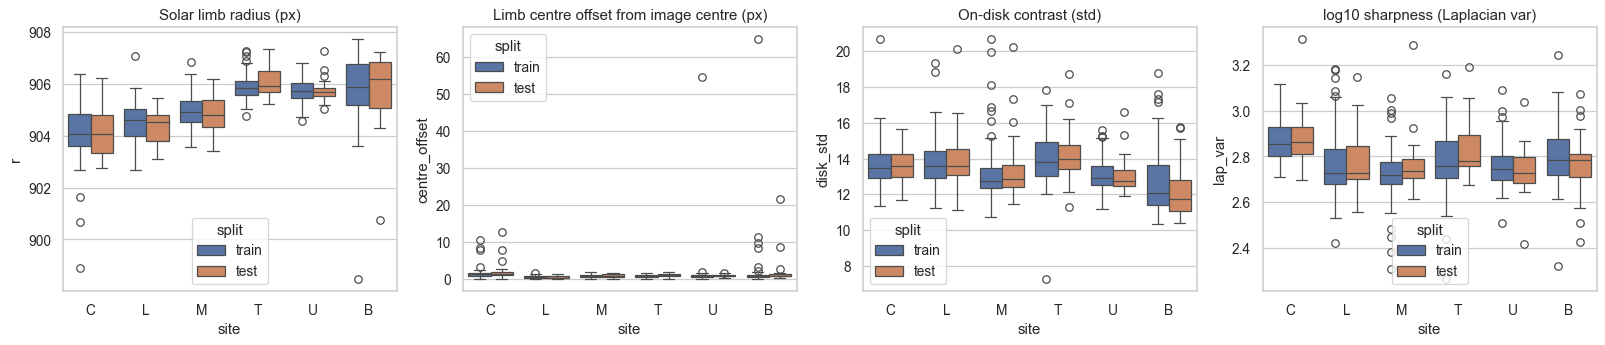

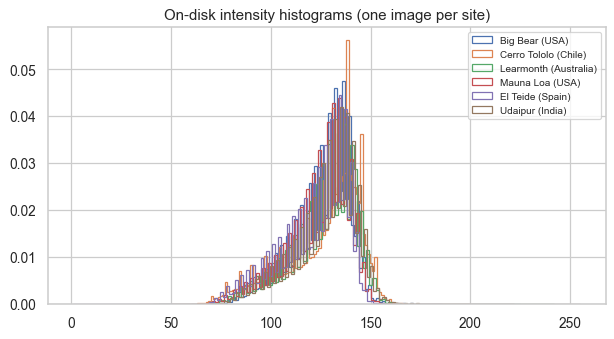

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
sns.boxplot(data=img_stats, x="site", y="r", hue="split", ax=ax[0]); ax[0].set_title("Solar limb radius (px)")
sns.boxplot(data=img_stats, x="site", y="centre_offset", hue="split", ax=ax[1]); ax[1].set_title("Limb centre offset from image centre (px)")
sns.boxplot(data=img_stats, x="site", y="disk_std", hue="split", ax=ax[2]); ax[2].set_title("On-disk contrast (std)")
sns.boxplot(data=img_stats, x="site", y=np.log10(img_stats.lap_var), hue="split", ax=ax[3]); ax[3].set_title("log10 sharpness (Laplacian var)")
plt.tight_layout(); plt.show()

# intensity histograms per site (train sample)
fig, ax = plt.subplots(figsize=(8, 4))
for s in sorted(SITES):
    fn = obs_df[obs_df.site == s].file_name.iloc[0]
    g = cv2.imread(str(TRAIN_IMG_DIR / fn), cv2.IMREAD_GRAYSCALE)
    cx, cy, r = img_stats.set_index("file_name").loc[fn, ["cx", "cy", "r"]]
    yy_, xx_ = np.ogrid[:IMG_SIZE, :IMG_SIZE]
    ax.hist(g[(xx_ - cx) ** 2 + (yy_ - cy) ** 2 <= (0.98 * r) ** 2].ravel(), bins=128, histtype="step", density=True, label=SITES[s])
ax.set_title("On-disk intensity histograms (one image per site)"); ax.legend(fontsize=8); plt.show()

**Interpretation.**
- *Limb radius:* all sites lie between ~898 and 908 px. Site differences are under 0.3%, too small to matter.
- *Centre offset:* almost all images are within 2 px of the centre. The few large values are the 9 failed fits, which were replaced by the default geometry.
- *Contrast and sharpness:* orange (test) boxes overlap blue (train) boxes for every site. The test set holds no new kind of image.
- *Histogram:* the on-disk brightness distributions of the six sites have the same shape and peak (~130–140). Site differences in brightness are mild, and per-image normalisation (Section 9) is enough to remove them.

**What & why: finding noisy observations.** The brief asks us to look at noisy samples. The competition lists "background noise and image quality" as a main difficulty because the images come from ground-based telescopes. MAGFiLO removed strongly anomalous images *before* annotation (paper, "Anomaly Detection and Removal"), but some may remain. We flag an image when one of its measurements is far from typical. We use robust z-scores (median and MAD, so the outliers themselves don't distort the scale), with a threshold of 4. Saturation uses a fixed rule (> 0.1% saturated pixels), because most images have none and a z-score is meaningless there.

In [7]:
def robust_z(x):
    med = np.median(x); mad = np.median(np.abs(x - med)) * 1.4826
    if mad < 1e-12:            # degenerate (e.g. mostly-zero feature): fall back to the std
        mad = x.std()
    return (x - med) / (mad + 1e-12)

Z_THR = 4.0
SAT_MAX = 1e-3
# every score is oriented so that "large positive" = bad
checks = {
    "odd_radius": np.abs(robust_z(img_stats.r.values)),
    "off_centre": robust_z(img_stats.centre_offset.values),
    "limb_fit_failed": (~img_stats.limb_fit_ok.values) * (Z_THR + 1.0),
    "blurry": -robust_z(np.log(img_stats.lap_var.values)),
    "uneven": robust_z(img_stats.cell_std.values),
    "dark_regions": robust_z(img_stats.dark_frac.values),
    # most disks have 0 saturated pixels, so a z-score is meaningless; flag > 0.1% saturated disk pixels instead
    "saturated": (img_stats.sat_frac.values > SAT_MAX) * (Z_THR + 1.0),
}
Z = pd.DataFrame(checks, index=img_stats.index)
img_stats["anomaly"] = Z.gt(Z_THR).apply(lambda r: ",".join(r.index[r]), axis=1)
img_stats["anomaly_score"] = Z.max(axis=1)
flagged = img_stats[img_stats["anomaly"] != ""].copy()
flagged["score"] = flagged.anomaly_score
flagged = flagged.sort_values("score", ascending=False)
print(f"flagged: {len(flagged)} / {len(img_stats)}  (train {sum(flagged.split=='train')}, test {sum(flagged.split=='test')})")
print(flagged["anomaly"].str.split(",").explode().value_counts().to_dict())
display(flagged[["split", "file_name", "site", "anomaly", "score"]].head(15))

flagged: 87 / 887  (train 66, test 21)
{'dark_regions': 71, 'uneven': 31, 'off_centre': 15, 'limb_fit_failed': 9, 'odd_radius': 4, 'blurry': 3, 'saturated': 1}


,split,file_name,site,anomaly,score
680,train,20210721123430Ch.jpeg,C,"uneven,dark_regions",258.244224
426,train,20150629161614Mh.jpeg,M,"uneven,dark_regions",173.236450
688,train,20211016145050Bh.jpeg,B,"off_centre,limb_fit_failed,uneven,dark_regions",130.482227
304,train,20140428233234Lh.jpeg,L,"uneven,dark_regions",113.660076
691,train,20211225025850Uh.jpeg,U,"off_centre,limb_fit_failed,uneven,dark_regions",109.351613
790,test,20140710020754Uh.jpeg,U,dark_regions,89.296467
487,train,20160317232434Lh.jpeg,L,"uneven,dark_regions",83.466775
163,train,20121024164714Mh.jpeg,M,"uneven,dark_regions",71.996082
728,test,20111208173814Mh.jpeg,M,"uneven,dark_regions",48.181237
622,train,20180306081810Th.jpeg,T,"uneven,dark_regions",48.136551


**Interpretation.**
- **87 of 887 images are flagged (66 train, 21 test).** Reasons: dark regions 71, uneven illumination 31, off-centre 15 (mostly the 9 failed limb fits), odd radius 4, blurry 3, saturated 1.
- The dark-region check is deliberately sensitive. Clouds create dark patches, but so do very large filaments, so a flag means "look at this", not "this is broken".
- Importantly, **the test set is flagged at the same rate** (21/180 ≈ 12% vs 66/707 ≈ 9%). The same artefacts will be present when Kaggle scores us.

**What & why.** Numbers alone can't tell a cloud from a big filament, so we look at the 12 most extreme flagged images.

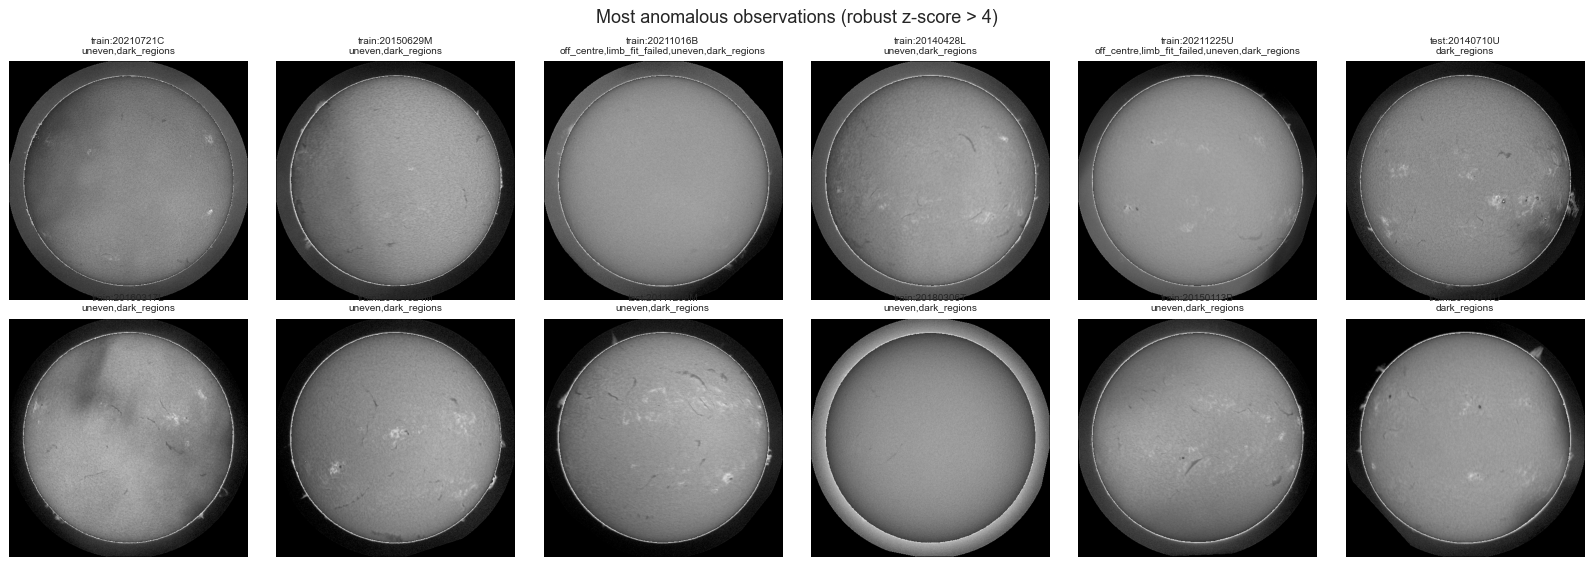

In [8]:
show = flagged.head(12)
if len(show):
    n = len(show); cols = 6; rws = math.ceil(n / cols)
    fig, axs = plt.subplots(rws, cols, figsize=(3 * cols, 3.2 * rws), squeeze=False)
    for axx, (_, r) in zip(axs.ravel(), show.iterrows()):
        d = TRAIN_IMG_DIR if r.split == "train" else TEST_IMG_DIR
        axx.imshow(cv2.imread(str(d / r.file_name), cv2.IMREAD_GRAYSCALE)[::4, ::4], cmap="gray")
        axx.set_title(f"{r.split}:{r.file_name[:8]}{r.site}\n{r.anomaly}", fontsize=8)
    for axx in axs.ravel(): axx.axis("off")
    plt.suptitle("Most anomalous observations (robust z-score > 4)"); plt.tight_layout(); plt.show()

**Interpretation.**
- We see real artefacts: **cloud or haze shading** (e.g. 2021-07-21 Cerro Tololo, and a clear diagonal cloud band in the bottom-left image), a second bright ring inside the disk where the limb fit failed (2021-10-16 Big Bear, 2021-12-25 Udaipur), and an unusual bright-halo exposure.
- In all of them **the solar disk and its filaments are still visible**, and they carry expert annotations.
- **Decision: keep all images.**
  1. The test set contains the same artefacts, so the model must learn to handle them. Removing them from training would make the model *less* robust.
  2. MAGFiLO already removed images where features were no longer discernible.
  3. Every removed image removes expert labels we can't replace.

  Brightness and blur augmentation (Section 10) adds more of this variation.

**What & why.** This is a single place to drop specific observations if the group decides an image is unusable after looking at the gallery above. Anything listed here is removed before the split and the export.

In [9]:
EXCLUDE_TRAIN = []   # fill in after visual review, e.g. ["2013xxxxxxxxxxLh"]
print("excluded observations:", EXCLUDE_TRAIN)

excluded observations: []


**Interpretation.** The list is empty. Based on the gallery, we keep everything. Note that if an image were excluded, its labels would go too.

## 4. What do the labels look like?
**What & why.** We draw the annotations on one typical image per site, plus a zoom on the largest filament, before computing statistics. This checks that labels line up with the image, and shows what the model will have to reproduce.

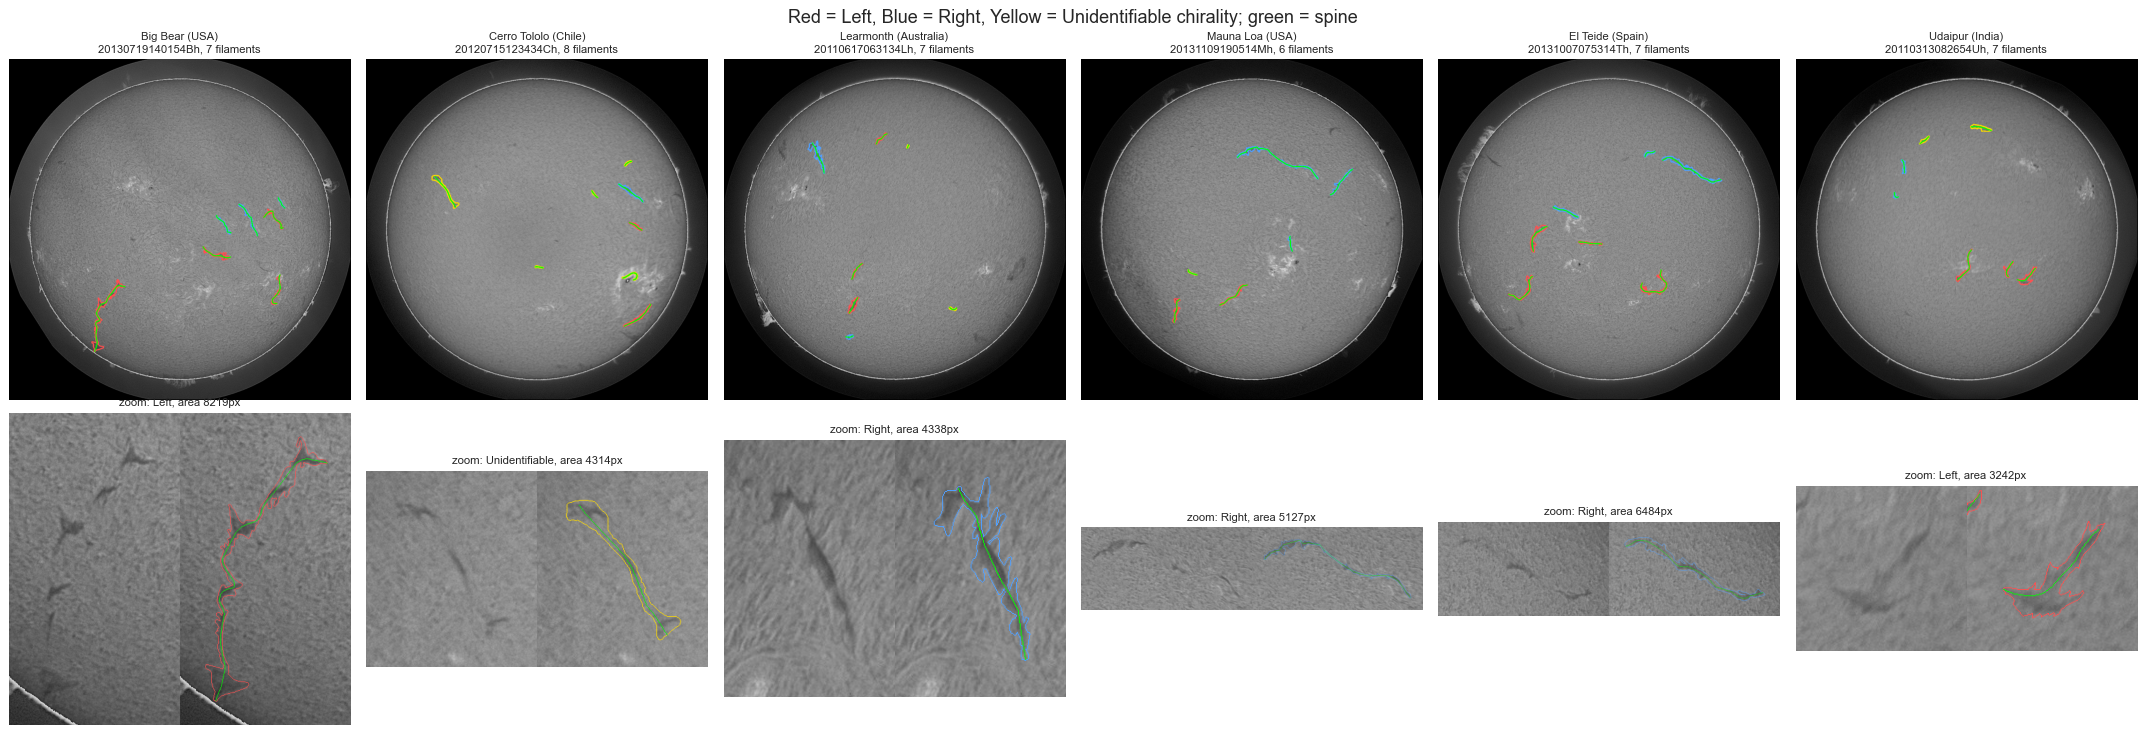

In [10]:
CAT_COLORS = {1: (255, 80, 80), 2: (80, 160, 255), 3: (255, 220, 0), 4: (200, 0, 200)}

def overlay(g, anns, thickness=3, spines=True):
    rgb = cv2.cvtColor(g, cv2.COLOR_GRAY2RGB)
    for a in anns:
        for seg in a["segmentation"]:
            cv2.polylines(rgb, [poly_pts(seg)], True, CAT_COLORS[a["category_id"]], thickness)
        if spines and a.get("spine"):
            cv2.polylines(rgb, [poly_pts(a["spine"])], False, (0, 255, 0), max(1, thickness - 1))
    return rgb

fig, axs = plt.subplots(2, 6, figsize=(24, 8.5))
for j, s in enumerate(sorted(SITES)):
    row = sets_df[(sets_df.site == s)].sort_values("n_filaments").iloc[len(sets_df[sets_df.site == s]) // 2]
    g = cv2.imread(str(TRAIN_IMG_DIR / row.file_name), cv2.IMREAD_GRAYSCALE)
    anns = anns_by_set[row.set_id]
    axs[0, j].imshow(overlay(g, anns, 6)[::2, ::2]); axs[0, j].set_title(f"{SITES[s]}\n{row.obs}, {len(anns)} filaments", fontsize=9)
    big = max(anns, key=lambda a: a["area"]); x, y, w, h = map(int, big["bbox"]); pad = 40
    crop = (slice(max(y - pad, 0), y + h + pad), slice(max(x - pad, 0), x + w + pad))
    axs[1, j].imshow(np.hstack([cv2.cvtColor(g[crop], cv2.COLOR_GRAY2RGB), overlay(g, anns, 1)[crop]]))
    axs[1, j].set_title(f"zoom: {CATS[big['category_id']]}, area {big['area']:.0f}px", fontsize=9)
for a in axs.ravel(): a.axis("off")
plt.suptitle("Red = Left, Blue = Right, Yellow = Unidentifiable chirality; green = spine"); plt.tight_layout(); plt.show()

**Interpretation.**
- The outlines sit exactly on the dark filaments. Labels and images are aligned, and the polygons are in the same pixel coordinates as the JPEGs.
- The zooms show the hard part: **barbs**, the small side branches visible on the Left (red) and Right (blue) filaments. Annotators were asked to capture them (paper, "Features"), and the competition names "fine-scale structures" as a main difficulty.
- **Unidentifiable** filaments (yellow) are drawn smoother, without barbs. The paper says annotators were told to minimise detail for this class.
- A filament can also lie close to the limb (Big Bear zoom). The model has to see the region near the edge of the disk too.

## 5. How big and how thin are the filaments?
**What & why.** Object size tells us what input resolution we can afford and how hard "fine structure" really is. For each filament we compute:
- its **area**
- its **length**, from the annotated spine polyline
- its **mean width** ≈ area ÷ length
- its **elongation**

category             Left    Right  Unidentifiable
area       count   2535.0   2590.0          3074.0
           mean    2269.2   2442.5          1724.8
           std     2572.2   2670.2          2886.0
           min       60.0      9.0            73.0
           5%       390.0    399.5           269.0
           50%     1438.0   1524.0           868.5
           95%     6812.4   7965.7          6165.4
           max    37739.0  21158.0         35251.0
spine_len  count   2535.0   2590.0          3074.0
           mean     168.3    178.1           104.4
           std      120.7    134.3            86.6
           min       20.1     18.7            12.1
           5%        51.3     52.3            34.0
           50%      134.9    139.3            78.3
           95%      418.2    452.7           260.3
           max     1105.0   1027.4           868.0
mean_width count   2535.0   2590.0          3074.0
           mean      12.1     12.2            13.7
           std        5.5      5.5             8.4
           min        0.7      0.1             3.1
           5%         5.7      5.9             5.4
           50%       10.9     11.1            11.2
           95%       22.9     22.8            29.9
           max       49.2     56.6            70.2
elongation count   2535.0   2590.0          3074.0
           mean       3.7      3.8             2.8
           std        1.2      1.6             0.9
           min        1.1      1.3             0.9
           5%         2.1      2.1             1.5
           50%        3.5      3.6             2.7
           95%        5.9      5.9             4.5
           max       11.6     57.4             7.7

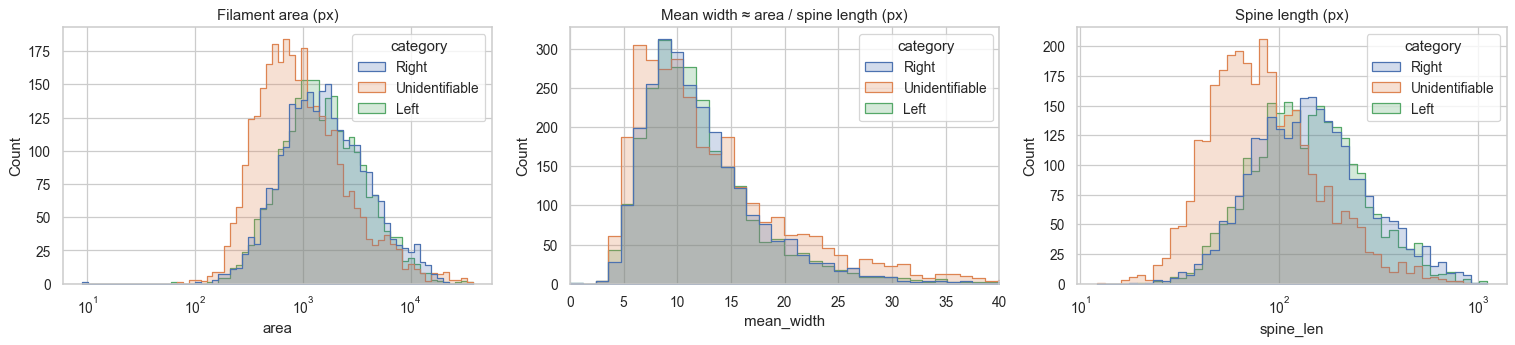

In [11]:
def polyline_length(p):
    p = np.asarray(p, float).reshape(-1, 2)
    return float(np.linalg.norm(np.diff(p, axis=0), axis=1).sum()) if len(p) > 1 else 0.0

ann_df["spine_len"] = ann_df.spine.map(polyline_length)
ann_df["mean_width"] = ann_df.area / ann_df.spine_len.clip(lower=1)       # area / length ≈ average thickness
ann_df["elongation"] = ann_df.spine_len / np.sqrt(ann_df.area)
ann_df["category"] = ann_df.category_id.map(CATS)

display(ann_df.groupby("category")[["area", "spine_len", "mean_width", "elongation"]]
        .describe(percentiles=[.05, .5, .95]).T.round(1))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(data=ann_df, x="area", hue="category", log_scale=True, element="step", ax=ax[0]); ax[0].set_title("Filament area (px)")
sns.histplot(data=ann_df, x="mean_width", hue="category", element="step", bins=60, ax=ax[1]); ax[1].set_title("Mean width ≈ area / spine length (px)")
ax[1].set_xlim(0, 40)
sns.histplot(data=ann_df, x="spine_len", hue="category", log_scale=True, element="step", ax=ax[2]); ax[2].set_title("Spine length (px)")
plt.tight_layout(); plt.show()

**Interpretation.**
- **Filaments are thin.** The median width is **~11 px**, and 5% are narrower than ~5.5 px, measured on the full 2048 px image. The median area is ~1,400 px for Left/Right and ~870 px for Unidentifiable.
- They are long and thin (elongation ~3.6 for Left/Right). Unidentifiable filaments are shorter (median spine 78 px vs ~135 px) and blobbier, matching the annotation guideline.
- *Meaning:* if we shrink the image 4× to 512 px, a typical filament becomes **~3 px** wide and the thin ones under 2 px. Section 7 measures what this does to PQ.

**What & why: class imbalance and instance separation.** We draw every annotation set and measure:
1. **Foreground coverage:** the share of pixels that are filament, i.e. how imbalanced the two classes are.
2. **Touching/overlapping filaments.** PQ is an instance metric. If filaments often touched, a model that only predicts "filament / not filament" couldn't separate them.
3. **The "connected-components ceiling":** take a *perfect* filament/background mask, split it into blobs, and score it with PQ. This tells us how much a simple pipeline loses purely from instance splitting.
4. **Annotations outside the Sun**, which also checks the limb detection.

In [12]:
geo = img_stats.set_index("file_name")[["cx", "cy", "r"]]
K3, K11 = np.ones((3, 3), np.uint8), np.ones((11, 11), np.uint8)
set_rows = []
for sid, fn in tqdm(zip(sets_df.set_id, sets_df.file_name), total=len(sets_df)):
    anns = anns_by_set[sid]
    inst, count = rasterize_set(anns)
    fg = inst > 0
    touch0 = touch5 = 0
    for k, a in enumerate(anns, start=1):
        x, y, w, h = a["bbox"]; pad = 8
        x0, y0 = max(int(x) - pad, 0), max(int(y) - pad, 0)
        x1, y1 = min(int(x + w) + pad + 1, IMG_SIZE), min(int(y + h) + pad + 1, IMG_SIZE)
        local = ann_mask(a)[y0:y1, x0:x1]
        crop, cnt = inst[y0:y1, x0:x1], count[y0:y1, x0:x1]
        overl = (cnt[local > 0] > 1).any()
        n1 = np.setdiff1d(crop[cv2.dilate(local, K3) > 0], [0, k]).size > 0
        n5 = np.setdiff1d(crop[cv2.dilate(local, K11) > 0], [0, k]).size > 0
        touch0 += bool(overl or n1); touch5 += bool(overl or n1 or n5)
    n_cc, cc = cv2.connectedComponents(fg.astype(np.uint8), connectivity=8)
    cx, cy, r = geo.loc[fn]
    ys, xs = np.nonzero(fg)
    set_rows.append(dict(set_id=sid, n_inst=len(anns), coverage=fg.mean(), overlap_px=int((count > 1).sum()),
                         touching=touch0, within5px=touch5, n_cc=n_cc - 1,
                         cc_pq=panoptic_quality(inst, cc)["pq"],
                         outside_disk_frac=float((np.hypot(xs - cx, ys - cy) > r).mean()) if len(xs) else 0.0))
set_stats = pd.DataFrame(set_rows)
sets_df = sets_df.merge(set_stats, on="set_id")

tot = sets_df.n_inst.sum()
print(f"foreground coverage per set: mean {sets_df.coverage.mean()*100:.3f}%  median {sets_df.coverage.median()*100:.3f}%  max {sets_df.coverage.max()*100:.3f}%")
print(f"-> background:foreground ≈ {(1 - sets_df.coverage.mean()) / sets_df.coverage.mean():.0f}:1")
print(f"sets with overlapping polygons: {(sets_df.overlap_px > 0).sum()} / {len(sets_df)}")
print(f"instances touching another (≤1 px): {sets_df.touching.sum()} / {tot} ({sets_df.touching.sum()/tot*100:.1f}%)")
print(f"instances within 5 px of another : {sets_df.within5px.sum()} / {tot} ({sets_df.within5px.sum()/tot*100:.1f}%)")
print(f"connected components vs instances: {sets_df.n_cc.sum()} vs {tot}")
print(f"PQ ceiling of 'perfect semantic mask + connected components': {sets_df.cc_pq.mean():.4f} ± {sets_df.cc_pq.std():.4f}")
print(f"annotated pixels outside the disk radius: {sets_df.outside_disk_frac.mean()*100:.3f}% on average (max {sets_df.outside_disk_frac.max()*100:.2f}%)")

foreground coverage per set: mean 0.359%  median 0.302%  max 1.669%
-> background:foreground ≈ 278:1
sets with overlapping polygons: 5 / 1154
instances touching another (≤1 px): 20 / 8199 (0.2%)
instances within 5 px of another : 116 / 8199 (1.4%)
connected components vs instances: 8219 vs 8199
PQ ceiling of 'perfect semantic mask + connected components': 0.9973 ± 0.0160
annotated pixels outside the disk radius: 0.000% on average (max 0.00%)


**Interpretation.**
- **Severe class imbalance.** Filaments cover **0.36%** of an image on average (max 1.7%), which is **~278 background pixels for every filament pixel**. A model trained with plain pixel-wise loss can reach 99.6% accuracy by predicting "no filament" everywhere. Section 10 counters this.
- **Touching filaments are rare.** Only 20 of 8,199 (0.2%) touch another, and 5 of 1,154 sets have overlapping polygons. 116 (1.4%) are within 5 px of a neighbour, and these are the cases a slightly blurry prediction could merge.
- **The ceiling is 0.997.** A *perfect* mask split into blobs scores PQ **0.997**. *Meaning:* separating touching filaments is **not** the main challenge. The real challenge is getting each filament in **one piece** (fragmentation) and not inventing extra ones.
- 8,219 blobs vs 8,199 filaments: even some ground-truth polygons have such thin necks that they break into two blobs. This shows how easily thin filaments fragment, and supports the competition's emphasis on "structural continuity".
- **0% of annotated pixels lie outside the solar limb**, which confirms that the limb detection in Section 3 is correct.

**What & why.** We plot the distributions behind the numbers above: how much of each image is filament, whether that differs by site, and the connected-components PQ for each annotation set.

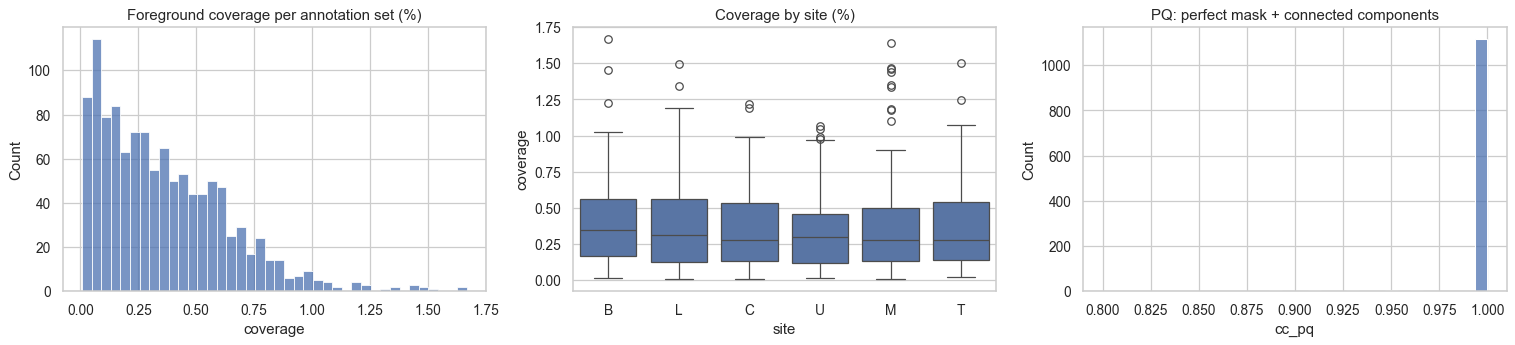

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(sets_df.coverage * 100, bins=40, ax=ax[0]); ax[0].set_title("Foreground coverage per annotation set (%)")
sns.boxplot(data=sets_df, x="site", y=sets_df.coverage * 100, ax=ax[1]); ax[1].set_title("Coverage by site (%)")
sns.histplot(sets_df.cc_pq, bins=30, ax=ax[2]); ax[2].set_title("PQ: perfect mask + connected components")
plt.tight_layout(); plt.show()

**Interpretation.**
- Coverage is low everywhere and skewed: most images are under 0.75% filament.
- No site is systematically different (similar boxes), so we don't need site-specific handling of imbalance.
- The ceiling histogram is a single spike at 1.0. For almost every image, splitting a perfect mask into blobs gives the correct instances. Instance trouble will come from *imperfect* masks (gaps and bridges), not from touching labels.

## 6. How much do the human annotators agree?
**What & why.** 296 photos have 2–3 independent annotation sets. We score annotator A against annotator B with the **competition metric**, treating one as "prediction" and the other as "truth". This tells us:
- **How noisy the labels are.** If humans disagree, the training targets are noisy.
- **A realistic ceiling.** A model is unlikely to agree with the annotators more than they agree with each other.

We also report SQ (how well matched masks overlap) and RQ (how many filaments are matched at all), the two factors of PQ.

annotator pairs: 598 from 296 observations
  pooled (Kaggle-style) PQ: 0.3397
          pq: 0.3407 ± 0.1648  (median 0.3416)
          sq: 0.5969 ± 0.1488  (median 0.6242)
          rq: 0.5376 ± 0.2493  (median 0.5420)
        dice: 0.6137 ± 0.1376  (median 0.6409)
  count_diff: 2.0452 ± 2.0593  (median 1.0000)


,pq,sq,rq,dice
site,,,,
Big Bear (USA),0.367,0.607,0.586,0.618
Cerro Tololo (Chile),0.335,0.602,0.530,0.598
Learmonth (Australia),0.350,0.601,0.545,0.619
Mauna Loa (USA),0.325,0.582,0.516,0.618
El Teide (Spain),0.338,0.585,0.526,0.612
Udaipur (India),0.326,0.605,0.516,0.613


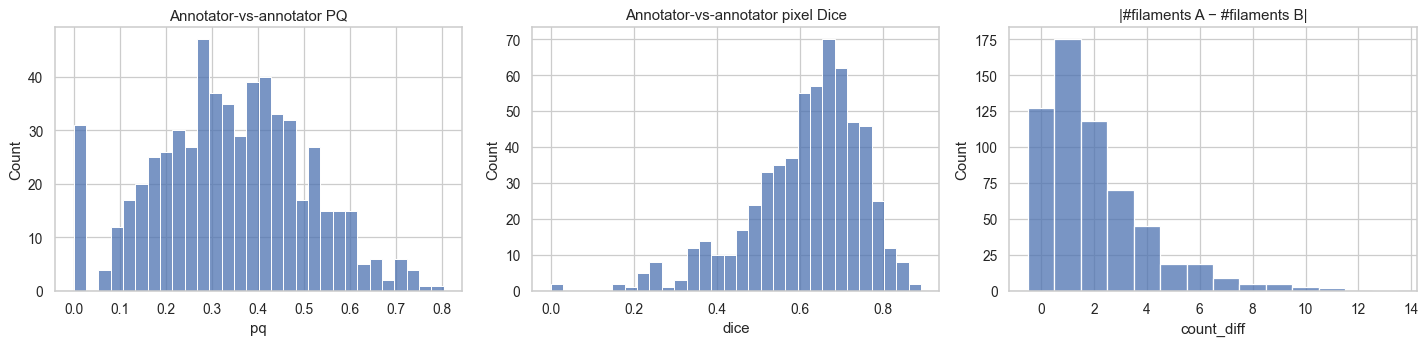

In [14]:
agree_rows = []
multi = sets_df.groupby("obs").filter(lambda d: len(d) > 1)
for obs, d in tqdm(multi.groupby("obs"), desc="annotator pairs"):
    maps = {sid: rasterize_set(anns_by_set[sid])[0] for sid in d.set_id}
    ids = list(maps)
    for i in range(len(ids)):
        for j in range(i + 1, len(ids)):
            a, b = maps[ids[i]], maps[ids[j]]
            fa, fb = a > 0, b > 0
            dice = 2 * (fa & fb).sum() / (fa.sum() + fb.sum() + 1e-9)
            pq = panoptic_quality(a, b)
            agree_rows.append(dict(obs=obs, site=d.site.iloc[0], set_a=ids[i], set_b=ids[j], dice=dice,
                                   n_a=len(np.unique(a)) - 1, n_b=len(np.unique(b)) - 1, **pq))
agree = pd.DataFrame(agree_rows)
agree["count_diff"] = (agree.n_a - agree.n_b).abs()
print(f"annotator pairs: {len(agree)} from {agree.obs.nunique()} observations")
print(f"  pooled (Kaggle-style) PQ: {global_pq(agree[['tp', 'fp', 'fn', 'iou_sum']].to_dict('records')):.4f}")
for m in ["pq", "sq", "rq", "dice", "count_diff"]:
    print(f"  {m:>10}: {agree[m].mean():.4f} ± {agree[m].std():.4f}  (median {agree[m].median():.4f})")
display(agree.groupby("site")[["pq", "sq", "rq", "dice"]].mean().round(3).rename(index=SITES))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(agree.pq, bins=30, ax=ax[0]); ax[0].set_title("Annotator-vs-annotator PQ")
sns.histplot(agree.dice, bins=30, ax=ax[1]); ax[1].set_title("Annotator-vs-annotator pixel Dice")
sns.histplot(agree.count_diff, discrete=True, ax=ax[2]); ax[2].set_title("|#filaments A − #filaments B|")
plt.tight_layout(); plt.show()

**Interpretation.**
- **Human vs human PQ is only 0.34** (pooled the Kaggle way: 0.340; per pair 0.341 ± 0.165). Pixel Dice is 0.61.
- **The main disagreement is about *which* structures are filaments:** RQ is only 0.54. Edges agree better (SQ 0.60). Two annotators of the same image differ by **2 filaments on average**, and 31 pairs share no matched filament at all (PQ = 0).
- It is similar for every site (0.33–0.37), so no instrument is "harder to label".
- *Meaning for us:*
  1. A PQ around **0.34–0.35 is roughly human level**. This matches the organisers' note that "any PQ score of greater than 0.35 is of great value" (Kaggle Announcements, 20 Aug 2026).
  2. The labels are noisy. We should not over-trust any single annotation set, and must not judge models on one annotator only.
- **Decision:** during training, each time a photo is used we pick **one of its annotation sets at random**, so the model sees the spread of human opinion. During validation we score against **every** set and pool, which is exactly how Kaggle scores (self-evaluation code). A soft (averaged) mask is also exported as an alternative target.

**What & why.** We show one photo with typical agreement and its three independent annotations side by side, to make the disagreement concrete.

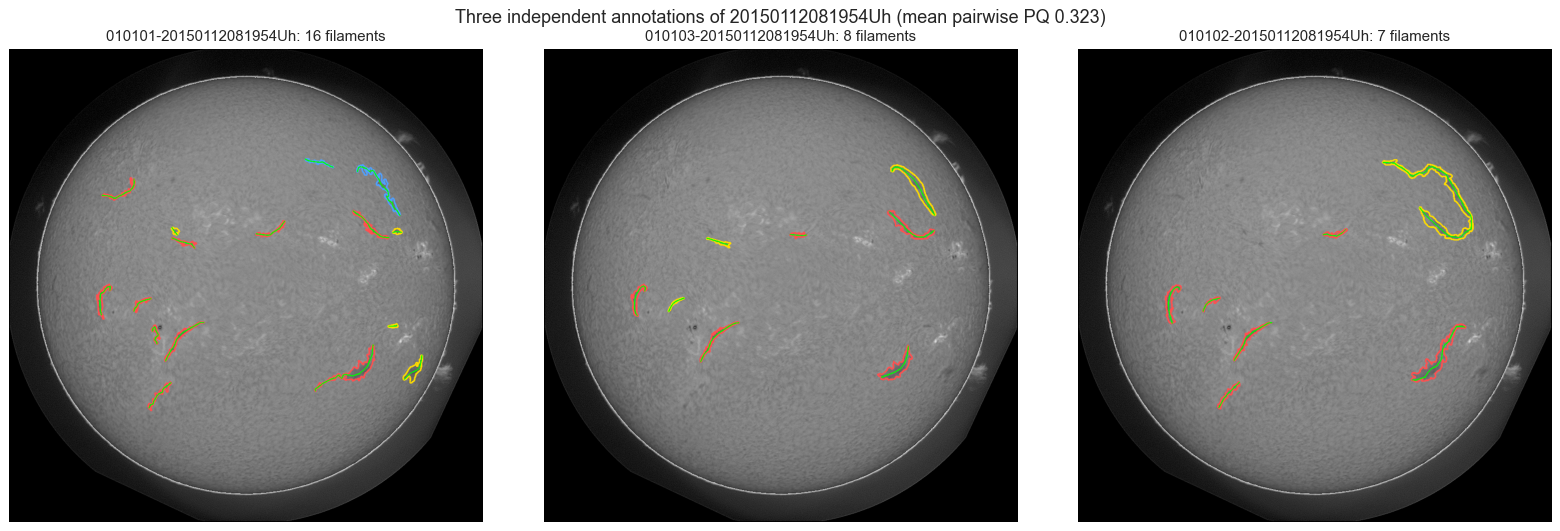

In [15]:
# visual: median-agreement observation with 3 sets
tri = agree.groupby("obs").pq.mean()
tri = tri[tri.index.isin(sets_df.groupby("obs").filter(lambda d: len(d) == 3).obs)]
obs_show = (tri - tri.median()).abs().idxmin()
d = sets_df[sets_df.obs == obs_show]
g = cv2.imread(str(TRAIN_IMG_DIR / d.file_name.iloc[0]), cv2.IMREAD_GRAYSCALE)
fig, axs = plt.subplots(1, len(d), figsize=(6 * len(d), 6))
for axx, sid in zip(np.atleast_1d(axs), d.set_id):
    axx.imshow(overlay(g, anns_by_set[sid], 5)[::2, ::2]); axx.set_title(f"{sid}: {len(anns_by_set[sid])} filaments"); axx.axis("off")
plt.suptitle(f"Three independent annotations of {obs_show} (mean pairwise PQ {tri[obs_show]:.3f})"); plt.tight_layout(); plt.show()

**Interpretation.**
- The three annotators found **16, 8 and 7 filaments** on the same image.
- The first one also outlined many small, faint structures that the others ignored.
- For the big filament at the top right, one annotator drew it as **one piece** while the others split it differently.

PQ punishes exactly these choices (extra filaments are FP, split filaments fail the IoU > 0.5 match). This is why the ceiling is low, and why we validate against all annotators.

## 7. How much resolution can we afford to lose?
**What & why.** Full 2048 px images are expensive, and the competition also scores efficiency, so downsampling is tempting. We test it on **perfect labels**: shrink each true instance map to a smaller size, enlarge it back, and score it against the original with PQ. Whatever is lost here is lost *before* the model makes a single mistake. It is an upper bound for any model working at that size.

,pq_mean,pq_std,instances_lost,median_width_px
size,,,,
2048,1.0000,0.0000,0.0,11.0807
1536,0.8456,0.0366,0.0,8.3106
1024,0.8844,0.0270,0.0,5.5404
768,0.7117,0.0875,0.0,4.1553
512,0.7004,0.0942,0.0,2.7702


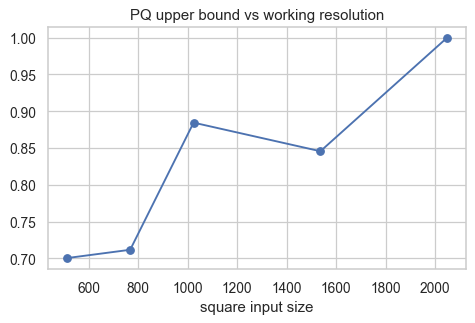

In [16]:
rng = np.random.default_rng(SEED)
sample_sets = rng.choice(sets_df.set_id.values, size=min(150, len(sets_df)), replace=False)
scales = [2048, 1536, 1024, 768, 512]
rows = []
for sid in tqdm(sample_sets, desc="scale analysis"):
    inst, _ = rasterize_set(anns_by_set[sid])
    n = len(np.unique(inst)) - 1
    for s in scales:
        down = cv2.resize(inst, (s, s), interpolation=cv2.INTER_NEAREST)
        up = cv2.resize(down, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
        res = panoptic_quality(inst, up)
        rows.append(dict(set_id=sid, size=s, pq=res["pq"], lost=(n - (len(np.unique(down)) - 1)) / max(n, 1)))
scale_df = pd.DataFrame(rows)
scale_summary = scale_df.groupby("size").agg(pq_mean=("pq", "mean"), pq_std=("pq", "std"), instances_lost=("lost", "mean")).sort_index(ascending=False)
scale_summary["median_width_px"] = ann_df.mean_width.median() * scale_summary.index / IMG_SIZE
display(scale_summary.round(4))
ax = scale_summary.pq_mean.plot(marker="o", figsize=(6, 3.5), title="PQ upper bound vs working resolution"); ax.set_xlabel("square input size"); plt.show()

**Interpretation.**

| Working size | Best possible PQ | Typical width at that size |
|---|---|---|
| 2048 (native) | 1.000 | 11 px |
| 1024 | 0.884 | 5.5 px |
| 768 | 0.712 | 4.2 px |
| 512 | 0.700 | 2.8 px |

- Shrinking to 512, the common default, **throws away ~30% of the achievable PQ**, because thin filaments break or merge when resampled. Even 1024 loses ~12%.
- 1536 scores 0.846, worse than 1024. 2048→1536 is not a whole-number ratio, so thin shapes get distorted more. If we ever downsample, we should use a factor of 2.
- **Decision:** keep **native resolution**. Train on **512×512 crops** of the full image, and predict on test images with an overlapping sliding window. The cost is compute, which the compression milestone has to handle.

## 8. A validation split we can trust
**What & why.** The brief is explicit:
- *"annotation sets of the same observation must never be divided between training and validation"*
- *"observations close in time, or from the same instrument, are not independent"*

Filaments live for days to weeks, and the Sun rotates once every ~27 days. So images taken a few days apart show **the same physical filaments**, and Section 1 found 119 train pairs less than a day apart. A random split would let the model "recognise" a filament it already saw in training, and our validation score would be too optimistic.

Our split:
- **Group by Carrington rotation** (the standard numbering of solar rotations, ~27.3 days). All images from one rotation, and therefore all views of a filament during that rotation, go into the same fold.
- **Stratify by site**, so every fold contains all six instruments in the same mix as the test set.
- **5 folds** (`StratifiedGroupKFold`). Fold 0 is the default hold-out set, and all 5 folds support mean ± std.
- The code **asserts** that no observation and no rotation appears in two folds.

In [17]:
def carrington_rotation(ts):
    jd = ts.timestamp() / 86400.0 + 2440587.5
    return int(math.floor(1690 + (jd - 2444235.34) / 27.2753))

obs_df["cr"] = obs_df.time.map(carrington_rotation)
test_df["cr"] = test_df.time.map(carrington_rotation)
obs_df = obs_df[~obs_df.obs.isin(EXCLUDE_TRAIN)].reset_index(drop=True)
print(f"Carrington rotations in train: {obs_df.cr.nunique()} (CR {obs_df.cr.min()}–{obs_df.cr.max()}), "
      f"observations per rotation: median {obs_df.cr.value_counts().median():.0f}, max {obs_df.cr.value_counts().max()}")

sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
obs_df["fold"] = -1
for f, (_, va) in enumerate(sgkf.split(obs_df, y=obs_df.site, groups=obs_df.cr)):
    obs_df.loc[va, "fold"] = f

cov = sets_df.groupby("obs").coverage.mean()
obs_df["coverage"] = obs_df.obs.map(cov)
bal = obs_df.groupby("fold").agg(observations=("obs", "size"), annotation_sets=("n_sets", "sum"),
                                 mean_filaments=("mean_filaments", "mean"), coverage_pct=("coverage", lambda x: x.mean() * 100),
                                 rotations=("cr", "nunique"), first=("time", "min"), last=("time", "max"))
display(bal.round(3))
display(pd.crosstab(obs_df.fold, obs_df.site, normalize="index").round(3).rename(columns=SITES))

# leakage checks
assert obs_df.groupby("cr").fold.nunique().max() == 1, "a rotation spans folds"
sets_df["fold"] = sets_df.obs.map(obs_df.set_index("obs").fold)
assert sets_df.dropna(subset=["fold"]).groupby("obs").fold.nunique().max() == 1, "an observation spans folds"
gaps = []
for f in range(N_FOLDS):
    tr = np.sort(obs_df[obs_df.fold != f].time.values.astype("int64"))
    va = obs_df[obs_df.fold == f].time.values.astype("int64")
    idx = np.clip(np.searchsorted(tr, va), 1, len(tr) - 1)
    near = np.minimum(np.abs(va - tr[idx - 1]), np.abs(va - tr[idx])) / 86400e9
    gaps.append(dict(fold=f, min_gap_days=near.min(), median_gap_days=np.median(near), val_within_3d_of_train=(near < 3).mean()))
display(pd.DataFrame(gaps).round(2))
print("leakage checks passed: no observation or rotation is shared between folds")

Carrington rotations in train: 130 (CR 2105–2260), observations per rotation: median 5, max 14


,observations,annotation_sets,mean_filaments,coverage_pct,rotations,first,last
fold,,,,,,,
0,139,232,7.668,0.391,28,2011-02-20 08:26:34,2022-04-18 02:09:50
1,138,227,7.685,0.368,27,2011-01-09 10:47:34,2022-07-18 18:53:52
2,145,241,6.807,0.302,27,2011-01-23 17:49:14,2022-06-22 20:56:32
3,142,234,6.919,0.334,24,2011-03-17 08:26:54,2022-01-04 04:30:50
4,143,220,7.732,0.386,24,2011-10-25 08:06:14,2022-08-03 07:47:52


site,Big Bear (USA),Cerro Tololo (Chile),Learmonth (Australia),Mauna Loa (USA),El Teide (Spain),Udaipur (India)
fold,,,,,,
0,0.165,0.173,0.180,0.180,0.158,0.144
1,0.174,0.174,0.181,0.174,0.152,0.145
2,0.166,0.179,0.186,0.172,0.152,0.145
3,0.162,0.183,0.176,0.176,0.155,0.148
4,0.168,0.175,0.175,0.182,0.161,0.140


,fold,min_gap_days,median_gap_days,val_within_3d_of_train
0,0,0.55,11.77,0.07
1,1,2.00,13.81,0.03
2,2,1.08,15.00,0.03
3,3,1.36,14.33,0.08
4,4,0.55,12.02,0.06


leakage checks passed: no observation or rotation is shared between folds


**Interpretation.**
- 130 rotations, a median of 5 photos each. The folds are balanced: 138–145 photos, 220–241 annotation sets, 24–28 rotations, 6.8–7.7 filaments per image, coverage 0.30–0.39%.
- Every fold has each site at 14–19%, the same mix as the test set.
- **Leakage checks pass.** No photo or rotation is shared between folds. The median time from a validation photo to the nearest training photo is **12–15 days**, about half a rotation, so validation filaments are mostly not the ones seen in training.
- **Known, small limitation:** 3–8% of validation photos are within 3 days of a training photo, where two rotations meet (minimum gap 0.55 days). A long-lived filament can cross that boundary. If our local and Kaggle scores ever disagree, the fix is to drop training photos within a few days of each validation block.
- Alternatives we rejected:
  - a random split, which leaks the same filaments
  - a split by year, since 2018–2022 hold only 14–42 photos each, giving unbalanced folds
  - leave-one-site-out as the main split, because the test set contains all sites. We keep it as an optional robustness check.

**What & why.** A timeline of every photo coloured by fold, with the test photos underneath, makes the grouping visible.

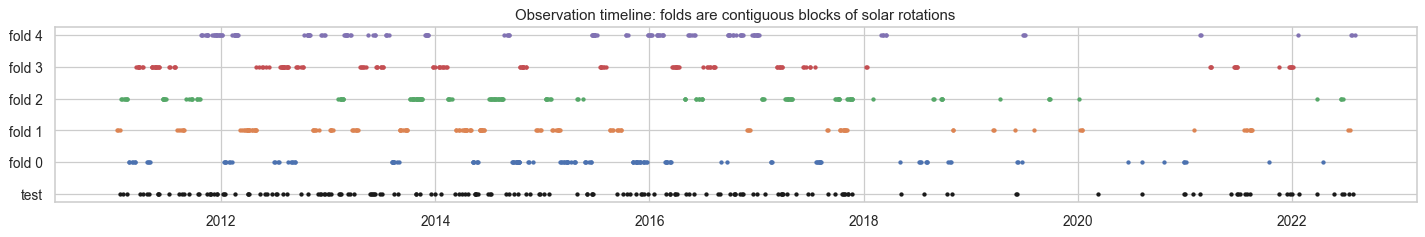

In [18]:
fig, ax = plt.subplots(figsize=(16, 2.8))
for f in range(N_FOLDS):
    t = obs_df[obs_df.fold == f].time
    ax.scatter(t, np.full(len(t), f), s=6, label=f"fold {f}")
ax.scatter(test_df.time, np.full(len(test_df), -1), s=6, c="k", label="test")
ax.set_yticks(range(-1, N_FOLDS)); ax.set_yticklabels(["test"] + [f"fold {f}" for f in range(N_FOLDS)])
ax.set_title("Observation timeline: folds are contiguous blocks of solar rotations"); plt.tight_layout(); plt.show()

**Interpretation.**
- Each fold is made of **blocks of consecutive weeks** (whole rotations), not scattered single days. That is the grouping working.
- Every fold still spans 2011–2022, so each one sees all phases of the solar cycle.
- The test photos (black) are spread over the same period, so validating on whole rotations mimics the test situation well.

## 9. Preprocessing
**What & why.** We want every image to arrive at the model in the same standard form, so the model spends its capacity on filaments rather than on instrument differences. Per image:
1. **Geometry:** shift and scale the image so the solar limb is centred with radius `CANON_R` (the median radius, 905 px). Section 3 showed GONG has already done this to within ~1 px, so this step is almost a no-op. It only corrects the few slightly off images.
2. **Intensity:** stretch the 1st–99th percentile of on-disk brightness to [0, 1]. This removes exposure and transparency differences between sites and days.
3. **Sky = 0:** set everything beyond 1.02 × the limb radius to zero. Section 5 found no annotation there, so the model doesn't need to learn the halo ring.

The transform is stored for every image so test predictions can be mapped back to the original 2048×2048 grid that Kaggle scores. We test this with a **round trip**: transform true masks forward and back, then score them with PQ.

In [19]:
CANON_SIZE, DISK_MARGIN = 2048, 1.02
CANON_R = round(R_MED)   # median solar-limb radius, so the warp is (almost) the identity for a typical image
C0 = (CANON_SIZE - 1) / 2

def canonical_affine(cx, cy, r):
    s = CANON_R / r
    return np.array([[s, 0, C0 - s * cx], [0, s, C0 - s * cy]], np.float32)

def warp(img, M, interp, size=CANON_SIZE):
    return cv2.warpAffine(img, M, (size, size), flags=interp, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

def from_canonical(mask_c, M, orig_hw=(IMG_SIZE, IMG_SIZE)):
    # Map a canonical-frame prediction (instance map or probabilities) back to the original image grid.
    interp = cv2.INTER_NEAREST if np.issubdtype(mask_c.dtype, np.integer) else cv2.INTER_LINEAR
    return cv2.warpAffine(mask_c, cv2.invertAffineTransform(M), (orig_hw[1], orig_hw[0]), flags=interp, borderValue=0)

yy, xx = np.ogrid[:CANON_SIZE, :CANON_SIZE]
DISK = (xx - C0) ** 2 + (yy - C0) ** 2 <= (CANON_R * DISK_MARGIN) ** 2

def normalise(img_c, lo=1, hi=99):
    v = img_c[DISK & (img_c > 0)]
    a, b = np.percentile(v, [lo, hi])
    out = np.clip((img_c.astype(np.float32) - a) / (b - a + 1e-6), 0, 1)
    out[~DISK] = 0
    return out

def preprocess(g, cx, cy, r):
    M = canonical_affine(cx, cy, r)
    return normalise(warp(g, M, cv2.INTER_LINEAR)), M

# round-trip verification of the geometry on 20 annotation sets
rt = []
for sid in rng.choice(sets_df.set_id.values, 20, replace=False):
    fn = sets_df.set_index("set_id").file_name[sid]
    inst, _ = rasterize_set(anns_by_set[sid]); cx, cy, r = geo.loc[fn]
    M = canonical_affine(cx, cy, r)
    back = from_canonical(warp(inst, M, cv2.INTER_NEAREST), M)
    rt.append(panoptic_quality(inst, back)["pq"])
print(f"canonical -> original round-trip PQ: {np.mean(rt):.4f} (min {np.min(rt):.4f})")

canonical -> original round-trip PQ: 0.9997 (min 0.9980)


**Interpretation.** Round-trip PQ is **0.9997** (worst 0.998). Mapping predictions back loses essentially nothing, so the preprocessing is safe to use in the final submission pipeline. Geometry was nearly perfect already, so the useful part of this step is the **intensity normalisation**.

**What & why.** We visually compare one raw image per site with its preprocessed version, plus the brightness histograms before and after.

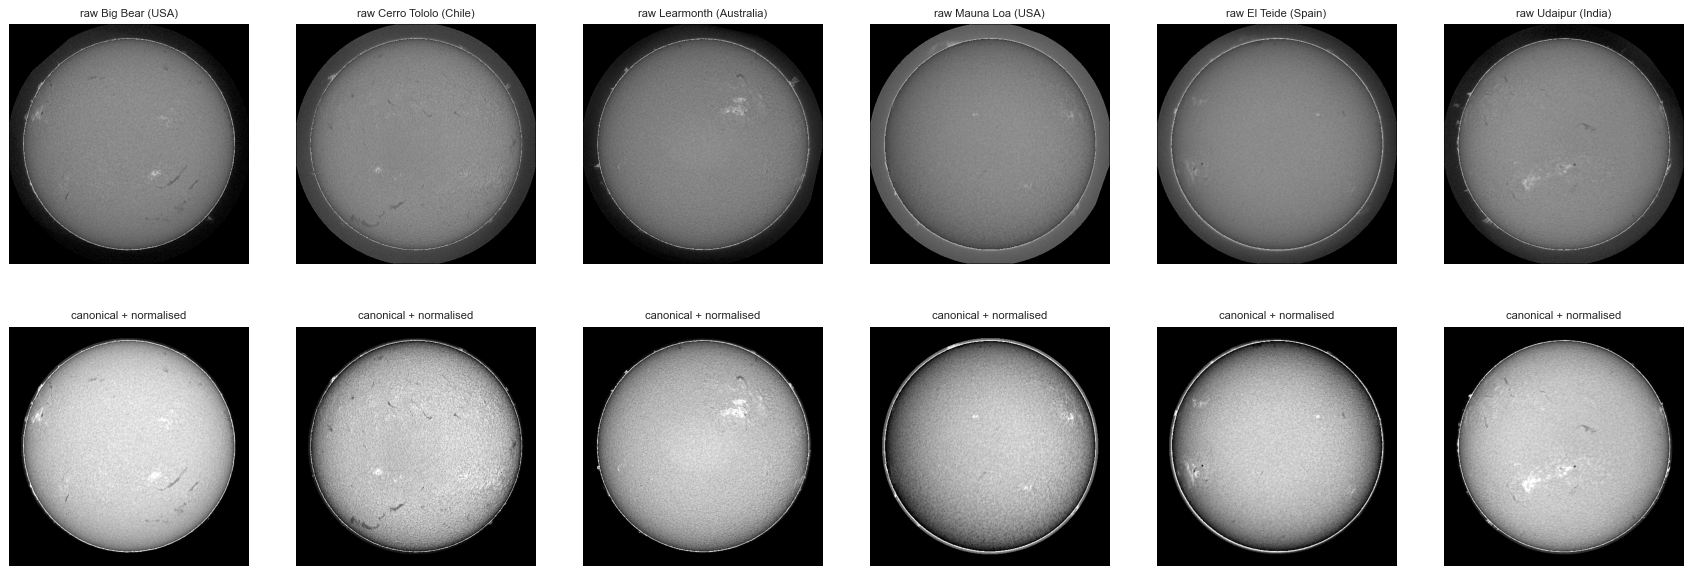

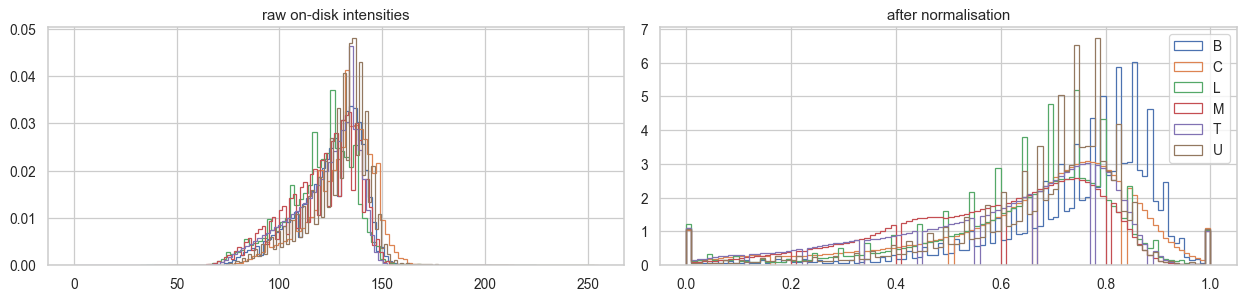

In [20]:
fig, axs = plt.subplots(2, 6, figsize=(24, 8))
fig2, ax2 = plt.subplots(1, 2, figsize=(14, 3.5))
for j, s in enumerate(sorted(SITES)):
    fn = obs_df[obs_df.site == s].file_name.iloc[3]
    g = cv2.imread(str(TRAIN_IMG_DIR / fn), cv2.IMREAD_GRAYSCALE)
    pre, M = preprocess(g, *geo.loc[fn])
    axs[0, j].imshow(g[::4, ::4], cmap="gray", vmin=0, vmax=255); axs[0, j].set_title(f"raw {SITES[s]}", fontsize=9)
    axs[1, j].imshow(pre[::4, ::4], cmap="gray", vmin=0, vmax=1); axs[1, j].set_title("canonical + normalised", fontsize=9)
    ax2[0].hist(g[(xx - C0) ** 2 + (yy - C0) ** 2 <= (0.98 * CANON_R) ** 2].ravel(), bins=100, histtype="step", density=True, label=s)
    ax2[1].hist(pre[DISK].ravel(), bins=100, histtype="step", density=True, label=s)
for a in axs.ravel(): a.axis("off")
ax2[0].set_title("raw on-disk intensities"); ax2[1].set_title("after normalisation"); ax2[1].legend()
plt.tight_layout(); plt.show()

**Interpretation.**
- After preprocessing, all six sites have a black sky and a disk that fills the same area. Filaments are clearly darker than their surroundings in every site.
- The histograms show the six sites' brightness ranges being brought onto the same 0–1 scale. The "comb" look of the right histogram is expected: stretching 8-bit values spreads them into evenly spaced bins.
- The Mauna Loa and El Teide examples keep a slightly darker rim near the limb. Some limb-brightness variation remains, so brightness augmentation is still useful.

## 10. Augmentation and dealing with class imbalance
**What & why.** 707 photos is a small dataset for deep learning, so augmentation creates realistic variations. Every augmentation is chosen for a physical reason:

| Augmentation | Why it is valid here |
|---|---|
| Rotation, any angle | The Sun is round and filaments occur at every orientation |
| Horizontal / vertical flips | Valid for the class-agnostic task. **Note:** a flip mirrors chirality (Left ↔ Right), which only matters if chirality is ever used as a target |
| Scale ±5% | Small size variation of filaments. Not needed for site differences (radius varies <0.3%, Section 3) |
| Gamma, contrast, brightness | Exposure and sky-transparency differences between days and sites (Sections 3 and 9) |
| Blur | Bad seeing; blurry images exist in train and test (Section 3) |
| Noise | Sensor/JPEG noise, the "background noise" difficulty named by the competition |
| **No elastic deformation** | It would bend and distort barbs, the fine structure we're scored on |

**Class imbalance:** with 278 background pixels per filament pixel (Section 5), random crops are often empty. So each crop is centred on a random filament pixel with probability `p_fg` (otherwise on a random point of the disk). This cell defines the crop and augmentation functions.

In [21]:
def patch_affine(center, patch, angle_deg=0.0, scale=1.0, flip_h=False, flip_v=False):
    # Affine mapping source (canonical) coords -> patch coords, rotating/scaling/flipping about `center`.
    t = math.radians(angle_deg)
    A = scale * np.array([[math.cos(t), -math.sin(t)], [math.sin(t), math.cos(t)]])
    A = A @ np.diag([-1.0 if flip_h else 1.0, -1.0 if flip_v else 1.0])
    half = (patch - 1) / 2
    b = np.array([half, half]) - A @ np.asarray(center, float)
    return np.hstack([A, b[:, None]]).astype(np.float32)

def photometric(img, rng):
    img = np.clip(img, 0, 1) ** rng.uniform(0.8, 1.25)
    img = (img - 0.5) * rng.uniform(0.85, 1.15) + 0.5 + rng.uniform(-0.05, 0.05)
    if rng.random() < 0.3:
        img = cv2.GaussianBlur(img, (0, 0), rng.uniform(0.5, 1.5))
    if rng.random() < 0.3:
        img = img + rng.normal(0, rng.uniform(0.005, 0.03), img.shape).astype(np.float32)
    return np.clip(img, 0, 1).astype(np.float32)

def instance_boundaries(inst):
    # 1-px boundary of every instance, including the contact line between touching instances.
    mx, mn = cv2.dilate(inst, K3), cv2.erode(inst, K3)
    return ((mx != mn) & (mx > 0)).astype(np.uint8)

def sample_center(fg_idx, rng, patch, p_fg):
    if len(fg_idx) and rng.random() < p_fg:
        y, x = divmod(int(rng.choice(fg_idx)), CANON_SIZE)
        return x + rng.uniform(-patch / 4, patch / 4), y + rng.uniform(-patch / 4, patch / 4)
    rr, th = CANON_R * math.sqrt(rng.random()), rng.uniform(0, 2 * math.pi)
    return C0 + rr * math.cos(th), C0 + rr * math.sin(th)

def make_patch(img_c, inst_c, rng, patch=512, p_fg=0.7, augment=True, fg_idx=None):
    if fg_idx is None:
        fg_idx = np.flatnonzero(inst_c)
    c = sample_center(fg_idx, rng, patch, p_fg)
    if augment:
        M = patch_affine(c, patch, rng.uniform(0, 360), rng.uniform(0.95, 1.05), rng.random() < 0.5, rng.random() < 0.5)
    else:
        M = patch_affine(c, patch)
    im = cv2.warpAffine(img_c, M, (patch, patch), flags=cv2.INTER_LINEAR, borderValue=0)
    ins = cv2.warpAffine(inst_c, M, (patch, patch), flags=cv2.INTER_NEAREST, borderValue=0)
    if augment:
        im = photometric(im, rng)
    return im, ins

**Interpretation.** Rotation, flip, scale and crop are combined into **one** transformation per crop. The image is resampled once, which keeps thin filaments sharper than chaining several resamples, and is cheaper. Masks use nearest-neighbour resampling, so labels stay crisp.

**What & why.** Two checks:
1. Do augmented crops still look realistic, and do labels stay aligned with the filaments?
2. How much does filament-centred sampling reduce the imbalance? We draw 300 crops of 512×512 for several `p_fg` values and measure the filament share and the share of empty crops.

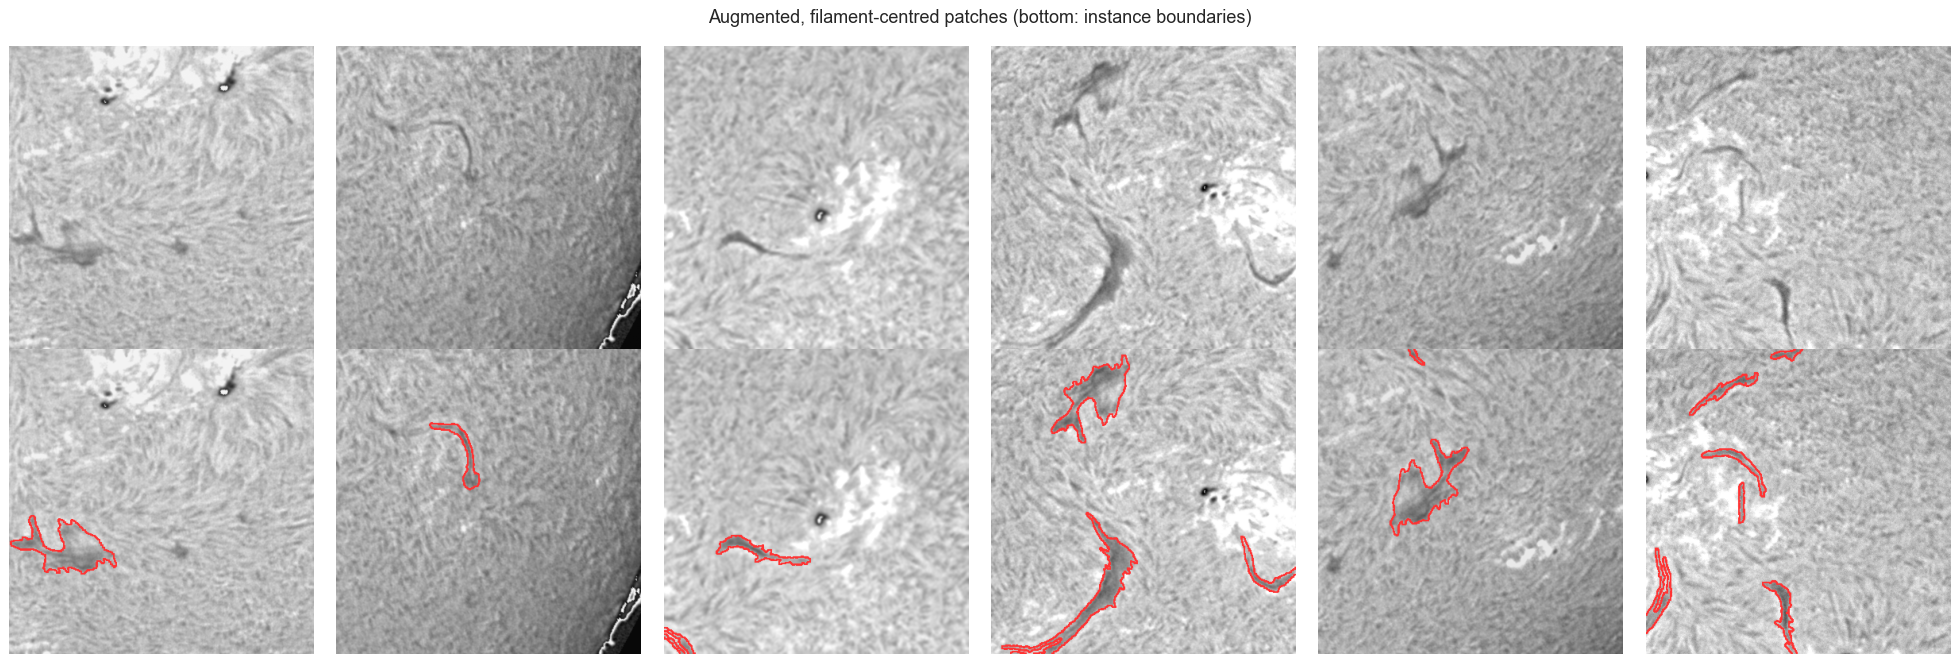

p_fg=0.0: mean foreground per 512-patch 0.71%  | empty patches 27%


p_fg=0.5: mean foreground per 512-patch 1.34%  | empty patches 16%


p_fg=0.7: mean foreground per 512-patch 1.83%  | empty patches 7%


p_fg=0.9: mean foreground per 512-patch 2.05%  | empty patches 4%
whole-image foreground: 0.40%


In [22]:
# demo on one observation: augmentation gallery + foreground fraction with/without biased sampling
demo = sets_df[sets_df.n_inst >= 8].iloc[0]
g = cv2.imread(str(TRAIN_IMG_DIR / demo.file_name), cv2.IMREAD_GRAYSCALE)
img_c, M = preprocess(g, *geo.loc[demo.file_name])
inst_c = warp(rasterize_set(anns_by_set[demo.set_id])[0], M, cv2.INTER_NEAREST)
fg_idx = np.flatnonzero(inst_c)

r = np.random.default_rng(1)
fig, axs = plt.subplots(2, 6, figsize=(22, 7.5))
for j in range(6):
    im, ins = make_patch(img_c, inst_c, r, patch=384, p_fg=1.0, augment=True, fg_idx=fg_idx)
    axs[0, j].imshow(im, cmap="gray", vmin=0, vmax=1)
    rgb = np.dstack([im] * 3); rgb[instance_boundaries(ins) > 0] = (1, 0.2, 0.2)
    axs[1, j].imshow(rgb)
for a in axs.ravel(): a.axis("off")
plt.suptitle("Augmented, filament-centred patches (bottom: instance boundaries)"); plt.tight_layout(); plt.show()

for p_fg in (0.0, 0.5, 0.7, 0.9):
    fr = [(make_patch(img_c, inst_c, r, 512, p_fg, False, fg_idx)[1] > 0).mean() for _ in range(300)]
    print(f"p_fg={p_fg:.1f}: mean foreground per 512-patch {np.mean(fr)*100:.2f}%  | empty patches {np.mean(np.array(fr)==0)*100:.0f}%")
print(f"whole-image foreground: {(inst_c > 0).mean()*100:.2f}%")

**Interpretation.**
- The red outlines follow the dark filaments in every rotated and flipped crop, so augmentation keeps labels aligned.
- Effect of filament-centred sampling:

| p_fg | Filament pixels per crop | Crops with no filament |
|---|---|---|
| 0.0 (random crops) | 0.71% | 27% |
| 0.5 | 1.34% | 16% |
| **0.7 (chosen)** | **1.83%** | **7%** |
| 0.9 | 2.05% | 4% |

- With `p_fg = 0.7` the model sees **~2.6× more filament pixels** and wastes far fewer steps on empty crops. That beats the whole-image share of 0.40%.
- We don't go to 0.9 because it adds little extra filament and the model then sees less pure background. Background matters, because every false filament costs ½ in PQ's denominator. `p_fg` remains a hyperparameter to tune on fold 0.
- Imbalance is not solved by sampling alone. The training milestone should also use an overlap-based loss (Dice/Tversky/Lovász) or a positive weight in BCE.

## 10b. Matching Kaggle's submission format and scoring exactly
**What & why.** A local score is only useful if it is computed exactly like Kaggle's. From the Kaggle pages and the organisers' self-evaluation code:
- `submission.csv` has **one row per predicted filament**: `filament_id` = `<image name>_<k>`, and `segmentation_rle` = pycocotools RLE counts string (size fixed at 2048×2048).
- Each **annotation set** is scored separately against all predictions for that image, then TP/FP/FN are pooled over everything.

This cell builds the encoder and a port of the organisers' scoring code, then runs three checks:
1. Encode → decode loses nothing.
2. Our masks equal Kaggle's ground-truth encoding.
3. **Our PQ equals the organisers' PQ** on real data. One annotator is used as the "prediction" and the others as truth, on fold 0.

In [23]:
def encode_mask(m):
    # Binary 2048x2048 mask -> RLE counts string expected by Kaggle.
    return mask_util.encode(np.asfortranarray(m.astype(np.uint8)))["counts"].decode("ascii")

def decode_rle(counts, h=IMG_SIZE, w=IMG_SIZE):
    return mask_util.decode({"size": [h, w], "counts": counts.encode("ascii")})

def instances_to_rows(stem, inst):
    # Instance map (original 2048 grid) -> submission rows for one image.
    return [dict(filament_id=f"{stem}_{k}", segmentation_rle=encode_mask(inst == k))
            for k in np.unique(inst) if k > 0]

def official_pq(gt_df, pred_df):
    # Port of the organisers' self-evaluation get_overlap_df + get_pq_score (numpy, same logic).
    gt_keys = gt_df.filament_id.str.split("_", n=1).str[0]
    pred_keys = pred_df.filament_id.str.split("_", n=1).str[0]
    tp_ious, fp, fn = [], 0, 0
    for ann_img in gt_keys.unique():
        stem = ann_img.split("-", 1)[1]
        g = np.stack([decode_rle(r).ravel() for r in gt_df.segmentation_rle[gt_keys == ann_img]]).astype(np.float32)
        p_r = pred_df.segmentation_rle[pred_keys == stem]
        if len(p_r) == 0:
            fn += len(g); continue
        p = np.stack([decode_rle(r).ravel() for r in p_r]).astype(np.float32)
        inter = g @ p.T
        union = g.sum(1)[:, None] + p.sum(1)[None] - inter
        iou = np.where(union > 0, inter / np.maximum(union, 1), 0)
        hit = iou > 0.5
        tp_ious += iou[hit].tolist(); fp += int((hit.sum(0) == 0).sum()); fn += int((hit.sum(1) == 0).sum())
    d = len(tp_ious) + 0.5 * fp + 0.5 * fn
    return sum(tp_ious) / d if d else 0.0

# Ground truth in Kaggle format, built directly from the COCO polygons
gt_rows = [dict(filament_id=f"{sid}_{k}", segmentation_rle=mask_util.frPyObjects(a["segmentation"], IMG_SIZE, IMG_SIZE)[0]["counts"].decode("ascii"))
           for sid in sets_df.set_id for k, a in enumerate(anns_by_set[sid], start=1)]
gt_rle_df = pd.DataFrame(gt_rows)

# Check 1: encoder round trip is lossless
sid0 = sets_df.set_id.iloc[0]; inst0, _ = rasterize_set(anns_by_set[sid0])
rows0 = instances_to_rows(sets_df.obs.iloc[0], inst0)
assert all((decode_rle(r["segmentation_rle"]) == (inst0 == k)).all() for k, r in enumerate(rows0, 1))
# Check 2: our rasterisation equals the official GT encoding
assert all((decode_rle(r["segmentation_rle"]) == (inst0 == k)).all()
           for k, r in enumerate(gt_rle_df[gt_rle_df.filament_id.str.startswith(sid0 + "_")].to_dict("records"), 1)) or (sets_df.overlap_px.iloc[0] > 0)

# Check 3: our PQ == official PQ. "Prediction" = first annotation set of each multi-annotated observation (fold 0),
# scored against all OTHER sets of that observation.
chk = sets_df[(sets_df.fold == 0)].groupby("obs").filter(lambda d: len(d) > 1)
pred_rows, ours, gt_ids = [], [], []
for obs, d in chk.groupby("obs"):
    p_inst, _ = rasterize_set(anns_by_set[d.set_id.iloc[0]])
    pred_rows += instances_to_rows(obs, p_inst)
    for sid in d.set_id.iloc[1:]:
        ours.append(panoptic_quality(rasterize_set(anns_by_set[sid])[0], p_inst)); gt_ids.append(sid)
gt_sub = gt_rle_df[gt_rle_df.filament_id.str.split("_", n=1).str[0].isin(gt_ids)]
off, mine = official_pq(gt_sub, pd.DataFrame(pred_rows)), global_pq(ours)
print(f"official-code PQ {off:.5f} | our pooled PQ {mine:.5f} | {len(gt_ids)} annotation sets")
assert abs(off - mine) < 5e-3, "local PQ disagrees with the official implementation"
print("submission encoder and local PQ verified against the organisers' code")

official-code PQ 0.34327 | our pooled PQ 0.34327 | 93 annotation sets
submission encoder and local PQ verified against the organisers' code


**Interpretation.** Organisers' code: **PQ 0.34327**. Our implementation: **PQ 0.34327**. They are identical on 93 annotation sets, and all assertions pass.
- *Meaning:* from now on the team can score any model locally and get the number Kaggle would give (on comparable data), without using our 5 submissions per day.
- The submission encoder is also verified, so the final `submission.csv` will be in the correct format.

## 11. Export the prepared dataset
**What & why.** We save everything the modelling milestone needs, so nobody has to repeat this work:

| File | Contents |
|---|---|
| `images/<obs>.png` | preprocessed image (train + test) |
| `instances/<set_id>.png` | one instance mask per annotation set (each filament has its own number) |
| `boundaries/<set_id>.png` | filament outlines, an optional extra target to help keep neighbours apart |
| `soft/<obs>.png` | average of all annotators (label uncertainty) |
| `train_observations.csv` | per photo: site, time, rotation, **fold**, quality flags, transform |
| `train_sets.csv` | per annotation set: fold, number of filaments, coverage, touching stats |
| `test_observations.csv` | per test photo: transform needed to map predictions back |
| `train_gt_rle.csv` | ground truth in Kaggle format + fold, for local scoring |
| `config.json` | every preprocessing setting |

In [24]:
if EXPORT:
    for sub in ("images", "instances", "boundaries", "soft"):
        (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)
    flags = img_stats.set_index("file_name")["anomaly"]
    obs_rows, t0 = [], time.time()
    for _, o in tqdm(obs_df.iterrows(), total=len(obs_df), desc="export train"):
        g = cv2.imread(str(TRAIN_IMG_DIR / o.file_name), cv2.IMREAD_GRAYSCALE)
        img_c, M = preprocess(g, *geo.loc[o.file_name])
        cv2.imwrite(str(OUT_DIR / "images" / f"{o.obs}.png"), (img_c * 255).round().astype(np.uint8))
        soft = np.zeros((CANON_SIZE, CANON_SIZE), np.float32)
        sids = sets_df[sets_df.obs == o.obs].set_id.tolist()
        for sid in sids:
            inst_c = warp(rasterize_set(anns_by_set[sid])[0], M, cv2.INTER_NEAREST)
            cv2.imwrite(str(OUT_DIR / "instances" / f"{sid}.png"), inst_c)
            cv2.imwrite(str(OUT_DIR / "boundaries" / f"{sid}.png"), instance_boundaries(inst_c) * 255)
            soft += inst_c > 0
        cv2.imwrite(str(OUT_DIR / "soft" / f"{o.obs}.png"), (soft / len(sids) * 255).round().astype(np.uint8))
        obs_rows.append(dict(obs=o.obs, file_name=o.file_name, site=o.site, time=o.time, cr=o.cr, fold=o.fold,
                             n_sets=len(sids), set_ids="|".join(sids), flags=flags[o.file_name],
                             **{f"M{i}": v for i, v in enumerate(M.ravel())}))
    pd.DataFrame(obs_rows).to_csv(OUT_DIR / "train_observations.csv", index=False)
    sets_df[sets_df.obs.isin(obs_df.obs)][["set_id", "obs", "site", "fold", "set_code", "n_inst", "coverage",
                                           "overlap_px", "touching", "within5px", "n_cc", "cc_pq"]].to_csv(OUT_DIR / "train_sets.csv", index=False)

    test_rows = []
    for _, o in tqdm(test_df.iterrows(), total=len(test_df), desc="export test"):
        g = cv2.imread(str(TEST_IMG_DIR / o.file_name), cv2.IMREAD_GRAYSCALE)
        img_c, M = preprocess(g, *geo.loc[o.file_name])
        cv2.imwrite(str(OUT_DIR / "images" / f"{o.obs}.png"), (img_c * 255).round().astype(np.uint8))
        test_rows.append(dict(obs=o.obs, file_name=o.file_name, site=o.site, time=o.time, cr=o.cr,
                              flags=flags[o.file_name], **{f"M{i}": v for i, v in enumerate(M.ravel())}))
    pd.DataFrame(test_rows).to_csv(OUT_DIR / "test_observations.csv", index=False)

    config = dict(seed=SEED, n_folds=N_FOLDS, split="StratifiedGroupKFold(y=site, groups=Carrington rotation)",
                  canon_size=CANON_SIZE, canon_r=CANON_R, disk_margin=DISK_MARGIN, disk_detection="solar-limb circle fit (720 rays, strongest outward gradient), fallback to image centre + median radius",
                  normalisation="per-image on-disk percentiles 1-99 -> [0,1], off-disk = 0",
                  excluded_observations=EXCLUDE_TRAIN, anomaly_z_threshold=Z_THR,
                  inverse_transform="cv2.warpAffine(pred, cv2.invertAffineTransform(M), (2048, 2048))",
                  augmentation=dict(rotation=[0, 360], scale=[0.95, 1.05], flips=True, gamma=[0.8, 1.25],
                                    contrast=[0.85, 1.15], brightness=[-0.05, 0.05], blur_p=0.3, noise_p=0.3),
                  patch=512, p_fg=0.7, rasterisation="pycocotools frPyObjects (identical to Kaggle GT)")
    gt_rle_df.assign(set_id=gt_rle_df.filament_id.str.split("_", n=1).str[0]) \
        .merge(sets_df[["set_id", "fold"]], on="set_id").drop(columns="set_id") \
        .to_csv(OUT_DIR / "train_gt_rle.csv", index=False)   # Kaggle-format GT (+ fold) for local scoring
    (OUT_DIR / "config.json").write_text(json.dumps(config, indent=2))
    size_mb = sum(p.stat().st_size for p in OUT_DIR.rglob("*") if p.is_file()) / 1e6
    print(f"exported to {OUT_DIR} in {time.time() - t0:.0f}s, {size_mb:.0f} MB")

exported to C:\Users\lusiz\Desktop\University of Pretoria\COS711-AI\Assignment 2\data_prep\prepared in 164s, 1383 MB


**Interpretation.**
- The export finished in under 3 minutes (1.4 GB): 887 images, 1,154 instance and boundary masks, 707 soft masks, and 8,199 ground-truth filaments in Kaggle format.
- The whole folder can be regenerated by re-running this notebook on the raw Kaggle data.

## 12. A ready-to-use PyTorch dataset
**What & why.** We wrap the exported data in a PyTorch `Dataset` so the training milestone can start immediately, and load one batch to prove it works. Each sample:
- picks a random training photo
- picks one of its annotation sets at random (Section 6 decision)
- cuts a filament-biased 512×512 crop (Section 10), augments it, and returns the image plus three targets: filament mask, boundary mask and instance map

train observations: 568 | val observations: 139


{'image': ((8, 1, 512, 512), torch.float32), 'semantic': ((8, 1, 512, 512), torch.float32), 'boundary': ((8, 1, 512, 512), torch.float32), 'instance': ((8, 512, 512), torch.int64)}


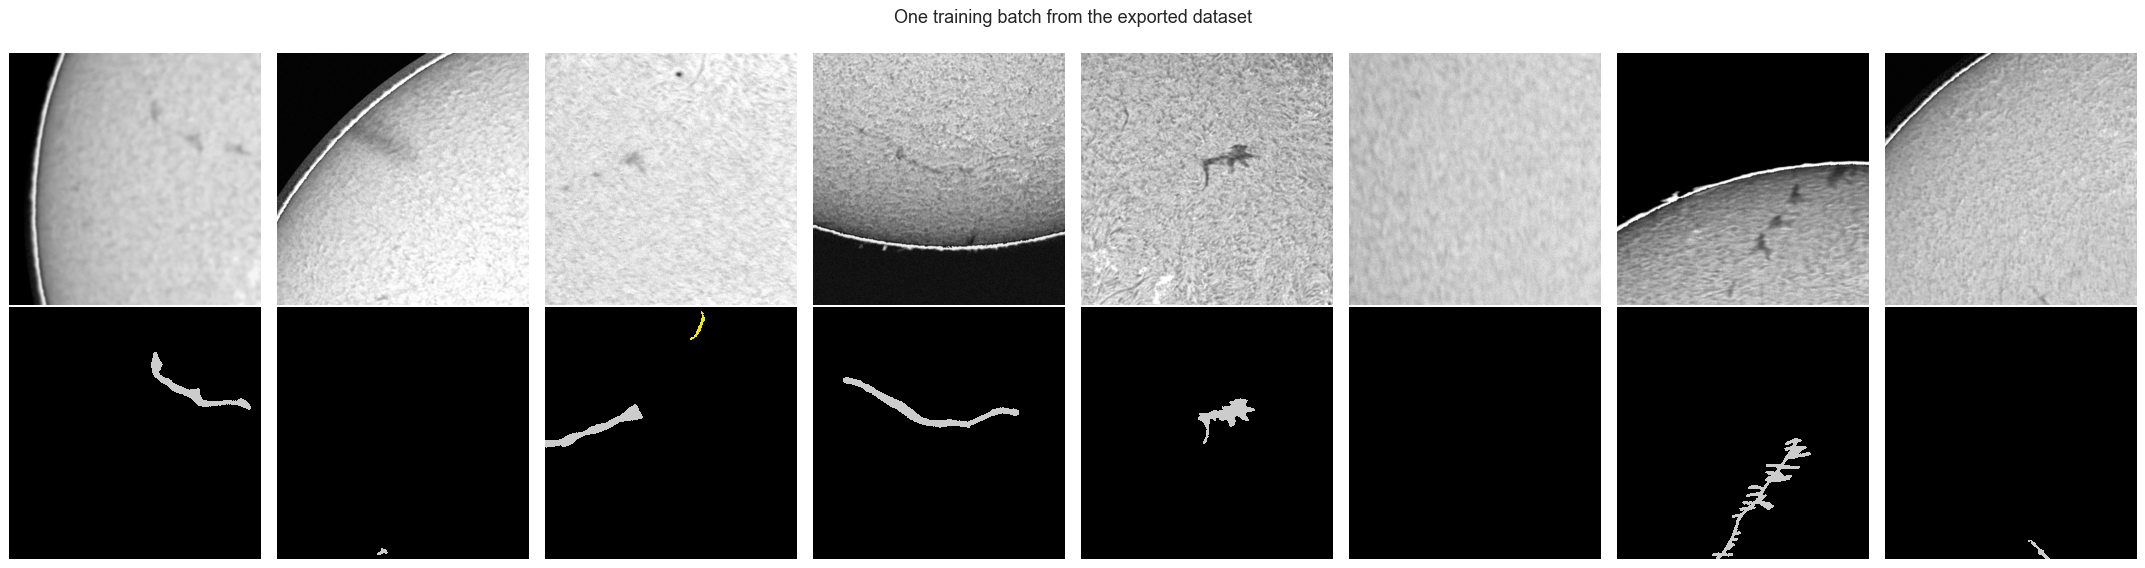

In [25]:
try:
    import torch
    from torch.utils.data import Dataset, DataLoader

    class FilamentPatchDataset(Dataset):
        # Patches from the prepared dataset. folds: list of fold ids to include.
        def __init__(self, root, folds, patch=512, p_fg=0.7, augment=True, samples_per_epoch=2000, seed=SEED):
            self.root = Path(root)
            obs = pd.read_csv(self.root / "train_observations.csv")
            self.obs = obs[obs.fold.isin(folds)].reset_index(drop=True)
            self.patch, self.p_fg, self.augment, self.n = patch, p_fg, augment, samples_per_epoch
            self.seed = seed

        def __len__(self):
            return self.n

        def __getitem__(self, i):
            # fresh randomness each call when augmenting; deterministic patches for validation
            rng = np.random.default_rng() if self.augment else np.random.default_rng((self.seed, i))
            o = self.obs.iloc[int(rng.integers(len(self.obs)))]
            sid = rng.choice(o.set_ids.split("|"))
            img = cv2.imread(str(self.root / "images" / f"{o.obs}.png"), cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255
            inst = cv2.imread(str(self.root / "instances" / f"{sid}.png"), cv2.IMREAD_UNCHANGED)
            im, ins = make_patch(img, inst, rng, self.patch, self.p_fg, self.augment)
            return dict(image=torch.from_numpy(im)[None],
                        semantic=torch.from_numpy((ins > 0).astype(np.float32))[None],
                        boundary=torch.from_numpy(instance_boundaries(ins).astype(np.float32))[None],
                        instance=torch.from_numpy(ins.astype(np.int64)),
                        obs=o.obs, set_id=sid)

    if EXPORT:
        train_ds = FilamentPatchDataset(OUT_DIR, folds=[1, 2, 3, 4], samples_per_epoch=16)
        val_ds = FilamentPatchDataset(OUT_DIR, folds=[0], augment=False, samples_per_epoch=8)
        print(f"train observations: {len(train_ds.obs)} | val observations: {len(val_ds.obs)}")
        batch = next(iter(DataLoader(train_ds, batch_size=8, num_workers=0)))
        print({k: (tuple(v.shape), v.dtype) for k, v in batch.items() if hasattr(v, "shape")})
        fig, axs = plt.subplots(2, 8, figsize=(24, 6.5))
        for j in range(8):
            axs[0, j].imshow(batch["image"][j, 0], cmap="gray", vmin=0, vmax=1)
            axs[1, j].imshow(batch["instance"][j], cmap="nipy_spectral", interpolation="nearest")
        for a in axs.ravel(): a.axis("off")
        plt.suptitle("One training batch from the exported dataset"); plt.tight_layout(); plt.show()
except ImportError:
    print("PyTorch not installed; skipping the Dataset demo")

**Interpretation.**
- Training uses folds 1–4 (568 photos) and validation uses fold 0 (139 photos). The batch shapes are as expected: images `(8, 1, 512, 512)`, masks `(8, 1, 512, 512)`, instance maps `(8, 512, 512)`.
- In the plotted batch, the masks match the dark filaments in the crops.
- One crop contains no filament (from the 30% random crops), and several crops lie on the solar edge. This is intended: the model must also learn what is *not* a filament, including the limb.

## 13. Summary
**What & why.** All key numbers in one place, for the slides and the team discussion.

In [26]:
summary = {
    "train observations / annotation sets / filaments": f"{len(obs_df)} / {len(sets_df)} / {len(ann_df)}",
    "test observations": len(test_df),
    "observations with 2 / 3 annotation sets": f"{(obs_df.n_sets == 2).sum()} / {(obs_df.n_sets == 3).sum()}",
    "image": "2048x2048 grayscale H-alpha, 6 GONG sites, 2011-2022",
    "disk radius px (mean ± std)": f"{img_stats.r.mean():.0f} ± {img_stats.r.std():.0f}",
    "median filament width px": round(float(ann_df.mean_width.median()), 1),
    "mean foreground coverage %": round(sets_df.coverage.mean() * 100, 3),
    "instances touching another %": round(sets_df.touching.sum() / sets_df.n_inst.sum() * 100, 1),
    "PQ ceiling: perfect mask + connected components": round(sets_df.cc_pq.mean(), 4),
    "PQ between human annotators (mean ± std)": f"{agree.pq.mean():.3f} ± {agree.pq.std():.3f}",
    "PQ ceiling at 512 / 1024 / 2048 input": " / ".join(f"{scale_summary.loc[s, 'pq_mean']:.3f}" for s in (512, 1024, 2048)),
    "flagged anomalous images (train / test)": f"{(flagged.split == 'train').sum()} / {(flagged.split == 'test').sum()}",
    "split": f"{N_FOLDS}-fold StratifiedGroupKFold (groups = Carrington rotation, stratified by site)",
}
for k, v in summary.items():
    print(f"{k:<52} {v}")

train observations / annotation sets / filaments     707 / 1154 / 8199
test observations                                    180
observations with 2 / 3 annotation sets              145 / 151
image                                                2048x2048 grayscale H-alpha, 6 GONG sites, 2011-2022
disk radius px (mean ± std)                          905 ± 1
median filament width px                             11.1
mean foreground coverage %                           0.359
instances touching another %                         0.2
PQ ceiling: perfect mask + connected components      0.9973
PQ between human annotators (mean ± std)             0.341 ± 0.165
PQ ceiling at 512 / 1024 / 2048 input                0.700 / 0.884 / 1.000
flagged anomalous images (train / test)              66 / 21
split                                                5-fold StratifiedGroupKFold (groups = Carrington rotation, stratified by site)


**Interpretation.** See the final decisions below.

## Final data-preparation decisions
Full reasoning with sources: `DATA_PREP_DECISIONS.md`.

| # | Decision | Main evidence (this notebook) |
|---|---|---|
| 1 | **Split:** 5 folds, grouped by solar rotation, stratified by site | Photos <24 h apart are common (§1). Leakage checks pass, median val→train gap 12–15 days (§8) |
| 2 | **Labels:** random annotation set per training sample; validate against all sets | Human vs human PQ only 0.34 (§6); Kaggle scores every set (§10b) |
| 3 | **Resolution:** native, 512 crops, sliding-window inference | Perfect labels at 512 already drop to PQ 0.70, at 1024 to 0.88 (§7); median width 11 px (§5) |
| 4 | **Imbalance:** filament-centred crops (`p_fg` 0.7) + overlap loss | 278:1 background:foreground (§5). Empty crops 27% → 7% (§10) |
| 5 | **Noisy images:** keep all | 87 flagged, but the test set has the same artefacts (21 flagged) and filaments stay visible (§3) |
| 6 | **Preprocessing:** limb-centred geometry + per-image intensity normalisation, sky = 0 | GONG disks already centred/scaled (radius 905 ± 1 px); round trip PQ 0.9997 (§9) |
| 7 | **Augmentation:** rotation, flips, small scale, brightness, blur, noise; no elastic | Each tied to a measured variation (§3, §9); elastic would distort barbs |
| 8 | **Next milestones should target continuity**, not touching instances | Perfect mask + blobs = PQ 0.997; only 0.2% touch (§5) |
| 9 | **Local PQ = Kaggle PQ** | 0.34327 vs 0.34327 (§10b) |

**Open questions for the group:**
1. Is native resolution affordable given the efficiency score, or do we use 1024 (factor 2)?
2. Do we add a few-day buffer around validation blocks?
3. Should chirality be used as an extra training signal (flips must then swap Left/Right)?